# Josué Uriel Martínez Ruíz

Colab: https://colab.research.google.com/drive/1hlt4NV5ozmVDNewhOjarGU3-YkeZd7Pw?usp=sharing

Github: https://github.com/josue-mtz/Deeplearning-para-vision-por-computadoras

#Deep Learning para visión de computadoras
##Lab 3.2 — DCGAN: implementación, estabilidad y diagnóstico
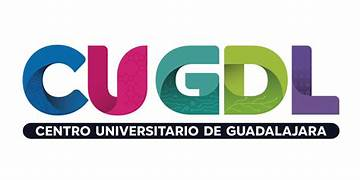

## Librerías

In [1]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid
from scipy import linalg
from IPython.display import display
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      "(" + torch.cuda.get_device_name(0) + ")" if DEVICE.type == "cuda" else "← activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4")

def fijar_semilla(s=0):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def mostrar_grid(x, titulo="", nrow=10, tam=(8, 8)):
    """x en [-1, 1], forma (N, C, H, W)."""
    g = make_grid(x.detach().cpu()[: nrow * nrow], nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=tam); plt.imshow(g.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off"); plt.title(titulo); plt.show()

PyTorch 2.14.1+cu130 | dispositivo: cuda (Tesla T4)


In [2]:
NOMBRES_CLASES = {
    "FashionMNIST": ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolsa", "botín"],
    "MNIST": [str(i) for i in range(10)],
    "CIFAR10": ["avión", "auto", "pájaro", "gato", "venado", "perro", "rana", "caballo", "barco", "camión"],
}

def cargar_tensor(nombre="FashionMNIST", split="train"):
    clase = getattr(datasets, nombre)
    ds = clase("datos", train=(split == "train"), download=True)
    x = torch.as_tensor(np.asarray(ds.data))
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    if x.ndim == 3:                          # escala de grises 28x28 → (N, 1, 32, 32) con relleno de 2 px
        x = F.pad(x.unsqueeze(1), (2, 2, 2, 2))
    else:                                    # CIFAR10 viene como (N, 32, 32, 3)
        x = x.permute(0, 3, 1, 2)
    x = x.float().div(255).mul(2).sub(1)    # [0, 255] → [-1, 1] (coincide con la tanh del generador)
    return x.to(DEVICE), y.to(DEVICE)

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):   # se descarta el último lote incompleto (BN lo agradece)
        j = idx[i:i + batch]
        yield x[j], y[j]

### Configuración
Adaptable "FashionMNIST" | "MNIST" | "CIFAR10"

In [3]:
CFG_BASE = dict(
    nombre="base",
    dataset="FashionMNIST",   # "FashionMNIST" | "MNIST" | "CIFAR10"
    nz=100, ngf=64, ndf=64,   # tamaño del ruido y anchura de G y D
    epocas=10, batch=128,
    lr_G=2e-4, lr_D=2e-4, beta1=0.5,      # valores del artículo DCGAN
    bn=True,                  # BatchNorm en G y D
    init_dcgan=True,          # pesos ~ N(0, 0.02)
    suavizado=0.9,            # one-sided label smoothing: etiqueta "real" = 0.9 (1.0 = sin suavizado)
    ruido_instancia=0.0,      # σ inicial de ruido gaussiano añadido a las entradas de D (decae a 0)
    pasos_D=1,                # actualizaciones de D por cada actualización de G
    semilla=0,
)

## Parte A

Cargamos **todo** el dataset en la GPU como un tensor de forma `(N, C, 32, 32)` con valores en **[−1, 1]** (rango de la `tanh` del generador). Las imágenes de 28×28 se rellenan con 2 píxeles para llegar a 32×32.

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.68MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 56.5MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.4MB/s]


Entrenamiento (60000, 1, 32, 32) · prueba (10000, 1, 32, 32) · rango [-1.0, 1.0]


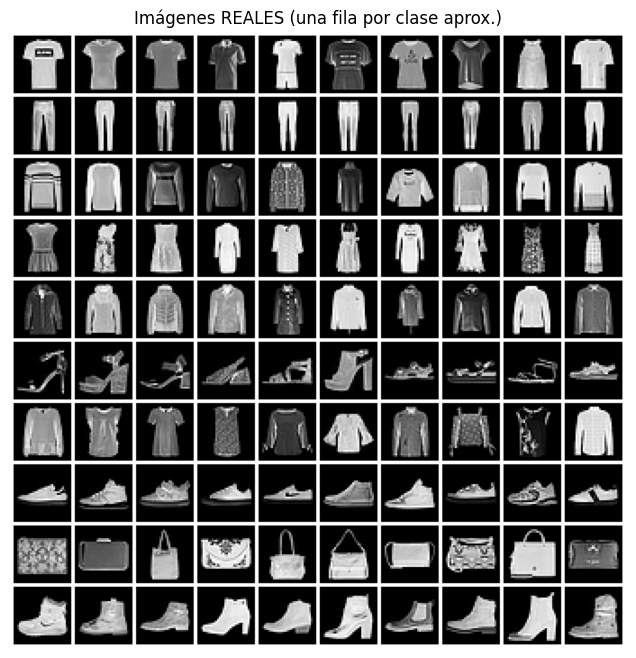

In [4]:
X_tr, Y_tr = cargar_tensor(CFG_BASE["dataset"], "train")
X_te, Y_te = cargar_tensor(CFG_BASE["dataset"], "test")
CANALES = X_tr.shape[1]
CLASES = NOMBRES_CLASES[CFG_BASE["dataset"]]
print(f"Entrenamiento {tuple(X_tr.shape)} · prueba {tuple(X_te.shape)} · rango [{X_tr.min():.1f}, {X_tr.max():.1f}]")
mostrar_grid(X_tr[torch.argsort(Y_tr)[::600]][:100], "Imágenes REALES (una fila por clase aprox.)")

## Parte B Arquitectura DCGAN para 32×32

Es la arquitectura del tutorial de [Pythorch](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html) con **una capa menos** (32×32 en lugar de 64×64).

Responde: ¿Cual es la diferencia entre la arquitectura GAN del articulo (2014) y DCGAN?

- **GAN:El generador y el discriminador son una redes fully connected, tambien no usa convoluciones ni normalización de manera sistemática, pero estas sufren problemas severos de mode collapse, gradientes inestables y sensibilidad extrema a hiperparámetros.**

- **DCGAN: En el generador usa convoluciones transpuestas, BatchNorm y activaciones ReLU, mientras que el discriminador usa convoluciones profundas, BatchNorm y activaciones LeakyReLU. Esto sirve para construir imágenes con estructura espacial coherente, mayor calidad , capacidad de distinguir patrones visuales y estabiliza el entrenamiento.**

**DCGAN no cambia la idea fundamental de las GAN pero si la formaliza la arquitectura convolucional profunda que hace que las GAN sean realmente entrenables y útiles para visión por computadora.**


Agrega el diagrama de la arquitectura en el notebook

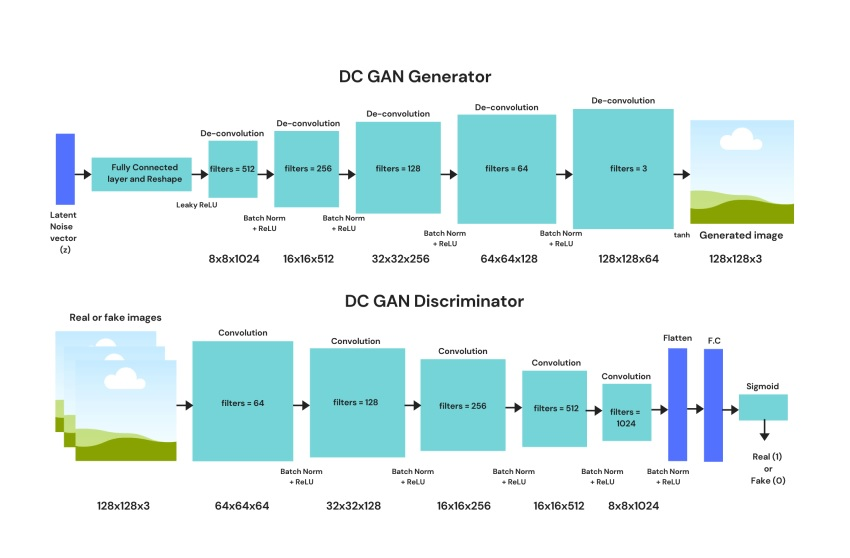

In [5]:
def _bn(n, usar):            # BatchNorm
    return nn.BatchNorm2d(n) if usar else nn.Identity()

class Generador(nn.Module):
    """DCGAN para 32x32: z (nz) → 4x4 → 8x8 → 16x16 → 32x32. Sin capas densas, solo convoluciones transpuestas."""
    def __init__(self, nz=100, ngf=64, canales=1, bn=True):
        super().__init__()
        b = not bn            # si hay BN el sesgo es redundante
        self.red = nn.Sequential(
            # Entrada: z es un vector (nz, 1, 1)
            nn.ConvTranspose2d(nz, ngf * 4, kernel_size=4, stride=1, padding=0, bias=b),
            _bn(ngf * 4, bn),
            nn.ReLU(True),
            # Estado actual: (ngf*4) x 4 x 4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ngf * 2, bn),
            nn.ReLU(True),
            # Estado actual: (ngf*2) x 8 x 8
            nn.ConvTranspose2d(ngf * 2, ngf, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ngf, bn),
            nn.ReLU(True),
            # Estado actual: (ngf) x 16 x 16
            nn.ConvTranspose2d(ngf, canales, kernel_size=4, stride=2, padding=1, bias=True),
            nn.Tanh()
            # Salida final: (canales) x 32 x 32
        )
    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    """Espejo del generador: convoluciones con stride 2 en lugar de pooling, LeakyReLU, y un LOGIT final.
    No ponemos Sigmoid: usamos BCEWithLogitsLoss, que es numéricamente estable."""
    def __init__(self, ndf=64, canales=1, bn=True):
        super().__init__()
        b = not bn
        self.red = nn.Sequential(
            # Entrada: (canales) x 32 x 32
            nn.Conv2d(canales, ndf, kernel_size=4, stride=2, padding=1, bias=True),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado actual: (ndf) x 16 x 16
            nn.Conv2d(ndf, ndf * 2, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ndf * 2, bn),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado actual: (ndf*2) x 8 x 8
            nn.Conv2d(ndf * 2, ndf * 4, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ndf * 4, bn),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado actual: (ndf*4) x 4 x 4
            nn.Conv2d(ndf * 4, 1, kernel_size=4, stride=1, padding=0, bias=True)
            # Salida final: 1 x 1 x 1
        )
    def forward(self, x):
        return self.red(x).view(-1)

def init_dcgan(m):
    """Inicialización del artículo DCGAN (Radford et al., 2016): pesos ~ N(0, 0.02); BN: γ ~ N(1, 0.02), β = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

In [6]:
G_demo = Generador(CFG_BASE["nz"], CFG_BASE["ngf"], CANALES).to(DEVICE)
D_demo = Discriminador(CFG_BASE["ndf"], CANALES).to(DEVICE)
print(G_demo, "\n", D_demo)
print(f"\nParámetros: G = {contar_parametros(G_demo):,} · D = {contar_parametros(D_demo):,}")

x = torch.randn(4, CFG_BASE["nz"], device=DEVICE)
print("\nRecorrido de formas del generador:")
h = x.view(4, -1, 1, 1)
for capa in G_demo.red:
    h = capa(h)
    if isinstance(capa, nn.ConvTranspose2d): print(f"  {capa.__class__.__name__:<16s} → {tuple(h.shape)}")
print("Salida de D (logits):", D_demo(h).shape)

Generador(
  (red): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Tanh()
  )
) 
 Discriminador(
  (red): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_si

## Parte C evaluador externo

Entrenamos una CNN pequeña con **imágenes reales** (3 épocas, ≈ 91 % de exactitud en FashionMNIST). Nunca ve imágenes generadas durante su entrenamiento. Luego la usamos para medir:

| Métrica | Cómo se calcula | Qué detecta |
|---|---|---|
| **Cobertura** | Nº de clases que reciben ≥ 2 % de las muestras generadas (de 10) | Colapso de modo **entre** clases |
| **Entropía** | Entropía de la distribución de clases predichas (máx. ln 10 ≈ 2.30) | Desbalance / colapso parcial |
| **Confianza** | Probabilidad máxima promedio que el juez asigna | Muestras ambiguas o "manchas" |
| **[FID](https://torchmetrics.readthedocs.io/en/v0.8.0/image/frechet_inception_distance.html) de dominio** | Distancia de Fréchet entre características (128-d) de reales y generadas | Calidad **y** diversidad a la vez  |

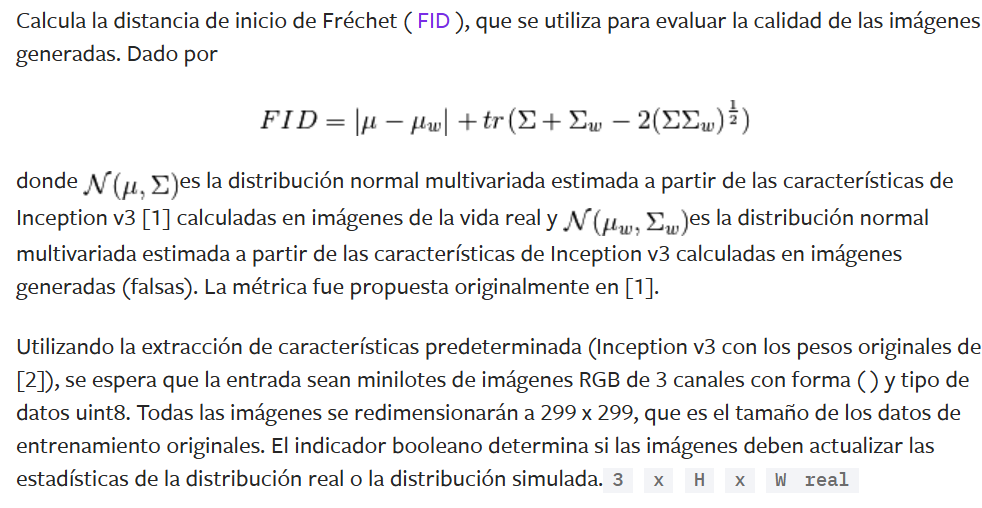

¿Cuales son las ventajas sobre la inspección visual? Explicalo con un ejemplo

**Siento que es como probar una comida, si uno la prueba y puedes decir "está rica", pero si la mandas a un laboratorio ahi te dicen: "le falta sal, tiene el doble de grasa y no tiene vitaminas", nuestra lengua nos dice si una cucharada está rica, pero el laboratorio nos dice si la comida entera está balanceada.**

**Con las GAN pasa igual:**

- **Ojo humano = prueba "una cucharada" (mira 20 – 30 imágenes).**

- **Juez + métricas = analiza las 1000 imágenes y te dice si están balanceadas o no.**

In [7]:
class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES. Nos sirve de 'evaluador externo' de las imágenes generadas:
    (1) qué clase cree que es cada muestra → cobertura de modos; (2) sus características de 128-d → FID de dominio."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),        # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:   # aumento "clásico": desplazamientos aleatorios de ±2 px y espejo horizontal
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

In [8]:
def estadisticos(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)

def distancia_frechet(mu1, s1, mu2, s2):
    """FID = ||μ1 − μ2||² + Tr(Σ1 + Σ2 − 2 (Σ1 Σ2)^{1/2})   (Heusel et al., 2017)"""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():          # estabilización numérica recomendada en la implementación oficial
        eps = np.eye(len(s1)) * 1e-6
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = np.real(covmean)
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_dominio(juez, x_a, x_b):
    return distancia_frechet(*estadisticos(juez.caracteristicas(x_a)), *estadisticos(juez.caracteristicas(x_b)))

In [9]:
JUEZ_RUTA = f"juez_{CFG_BASE['dataset']}.pt"
juez, acc_juez = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=3)
torch.save(juez.state_dict(), JUEZ_RUTA)

@torch.no_grad()
def metricas_generador(G, nz, n=2000, cond=None):
    """Métricas del juez sobre n muestras de G. 'cond' = etiquetas (solo para la cGAN del 5 de noviembre)."""
    G.eval()
    z = torch.randn(n, nz, device=DEVICE)
    xg = torch.cat([G(z[i:i + 500]) if cond is None else G(z[i:i + 500], cond[i:i + 500]) for i in range(0, n, 500)])
    G.train()
    p = juez.probabilidades(xg)
    frecuencia = torch.bincount(p.argmax(1), minlength=p.shape[1]).float() / n
    entropia = max(0.0, -(frecuencia * torch.log(frecuencia + 1e-12)).sum().item())
    return dict(cobertura=int((frecuencia >= 0.02).sum()), entropia=round(entropia, 3),
                confianza=round(p.max(1).values.mean().item(), 3),
                fid_dominio=round(fid_dominio(juez, X_te[:n], xg), 2)), xg, frecuencia.cpu()

print("Referencia — FID de dominio entre dos mitades de imágenes REALES:",
      round(fid_dominio(juez, X_te[:2000], X_tr[:2000]), 2))

Juez: exactitud en prueba real = 0.756
Referencia — FID de dominio entre dos mitades de imágenes REALES: 0.11


## Parte D Entrenamiento con registro completo

1. **Pérdida no saturante** para G y `BCEWithLogitsLoss` (estable numéricamente).
2. **Interruptores de estabilización** controlados desde `CFG`: *label smoothing*, ruido de instancia, BatchNorm, inicialización y pasos de D.
3. **Registro de todo**: pérdidas, $D(x)$, $D(G(z))$ antes y después de actualizar D, normas de los gradientes de G y D por iteración; métricas del juez y una rejilla con **ruido fijo** por época.

**Cómo leer las salidas de D** (tutorial de PyTorch): al inicio $D(x) \to 1$ y $D(G(z)) \to 0$; conforme G mejora, ambos deberían acercarse a 0.5 y oscilar alrededor de ese valor.

In [10]:
def norma_gradiente(modelo):
    return torch.sqrt(sum((p.grad.detach() ** 2).sum() for p in modelo.parameters() if p.grad is not None)).item()

def entrenar_dcgan(cfg, verbose=True):
    fijar_semilla(cfg["semilla"])
    G = Generador(cfg["nz"], cfg["ngf"], CANALES, bn=cfg["bn"]).to(DEVICE)
    D = Discriminador(cfg["ndf"], CANALES, bn=cfg["bn"]).to(DEVICE)
    if cfg["init_dcgan"]:
        G.apply(init_dcgan); D.apply(init_dcgan)
    opt_G = torch.optim.Adam(G.parameters(), lr=cfg["lr_G"], betas=(cfg["beta1"], 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=cfg["lr_D"], betas=(cfg["beta1"], 0.999))
    bce = nn.BCEWithLogitsLoss()
    z_fijo = torch.randn(100, cfg["nz"], device=DEVICE)          # mismo ruido en todas las épocas
    it_por_epoca = len(X_tr) // cfg["batch"]; total_it = cfg["epocas"] * it_por_epoca
    registro, por_epoca, rejillas = [], [], []
    it, t0, estado = 0, time.time(), "completado"
    for ep in range(cfg["epocas"]):
        for xr, _ in lotes(X_tr, Y_tr, cfg["batch"]):
            b = xr.size(0)
            sigma = cfg["ruido_instancia"] * max(0.0, 1 - it / total_it)      # el ruido decae linealmente
            ruido = (lambda t: t + sigma * torch.randn_like(t)) if sigma > 0 else (lambda t: t)
            # ---------- (1) Discriminador: maximizar log D(x) + log(1 − D(G(z))) ----------
            for _ in range(cfg["pasos_D"]):
                with torch.no_grad():
                    xf = G(torch.randn(b, cfg["nz"], device=DEVICE))
                out_r, out_f = D(ruido(xr)), D(ruido(xf))
                loss_D = bce(out_r, torch.full_like(out_r, cfg["suavizado"])) + bce(out_f, torch.zeros_like(out_f))
                opt_D.zero_grad(); loss_D.backward(); gD = norma_gradiente(D); opt_D.step()
            # ---------- (2) Generador: pérdida no saturante, minimizar −log D(G(z)) ----------
            xf = G(torch.randn(b, cfg["nz"], device=DEVICE))
            out_g = D(ruido(xf))
            loss_G = bce(out_g, torch.ones_like(out_g))
            opt_G.zero_grad(); loss_G.backward(); gG = norma_gradiente(G); opt_G.step()

            registro.append(dict(it=it, epoca=ep, loss_D=loss_D.item(), loss_G=loss_G.item(),
                                 D_x=torch.sigmoid(out_r).mean().item(), D_Gz_antes=torch.sigmoid(out_f).mean().item(),
                                 D_Gz_despues=torch.sigmoid(out_g).mean().item(), grad_D=gD, grad_G=gG))
            if not (math.isfinite(loss_D.item()) and math.isfinite(loss_G.item())):
                estado = f"DIVERGENCIA (NaN/inf) en la iteración {it}"; break
            it += 1
        if estado != "completado": break
        with torch.no_grad():
            G.eval(); rejillas.append(G(z_fijo).cpu()); G.train()
        met, _, frec = metricas_generador(G, cfg["nz"])
        por_epoca.append(dict(epoca=ep + 1, **met, frecuencias=frec.numpy().round(3)))
        if verbose:
            r = pd.DataFrame(registro[-it_por_epoca:]).mean()
            print(f"[{cfg['nombre']}] ép {ep + 1:>2}/{cfg['epocas']}  loss_D {r.loss_D:.3f}  loss_G {r.loss_G:.3f}  "
                  f"D(x) {r.D_x:.2f}  D(G(z)) {r.D_Gz_antes:.2f}→{r.D_Gz_despues:.2f}  | cobertura {met['cobertura']}/10  "
                  f"entropía {met['entropia']:.2f}  confianza {met['confianza']:.2f}  FID-d {met['fid_dominio']:.1f}  ({time.time() - t0:.0f} s)")
    return dict(cfg=cfg, G=G, D=D, registro=pd.DataFrame(registro), por_epoca=pd.DataFrame(por_epoca),
                rejillas=rejillas, estado=estado, segundos=round(time.time() - t0, 1))

base = entrenar_dcgan(CFG_BASE)
print("Estado:", base["estado"])

[base] ép  1/10  loss_D 0.580  loss_G 3.609  D(x) 0.79  D(G(z)) 0.11→0.06  | cobertura 3/10  entropía 0.73  confianza 0.74  FID-d 19.0  (21 s)
[base] ép  2/10  loss_D 0.705  loss_G 2.588  D(x) 0.73  D(G(z)) 0.17→0.13  | cobertura 8/10  entropía 1.60  confianza 0.72  FID-d 5.0  (43 s)
[base] ép  3/10  loss_D 0.807  loss_G 2.142  D(x) 0.69  D(G(z)) 0.21→0.17  | cobertura 8/10  entropía 1.80  confianza 0.74  FID-d 2.8  (65 s)
[base] ép  4/10  loss_D 0.827  loss_G 1.996  D(x) 0.68  D(G(z)) 0.22→0.19  | cobertura 8/10  entropía 1.96  confianza 0.74  FID-d 1.9  (88 s)
[base] ép  5/10  loss_D 0.849  loss_G 1.896  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 2.02  confianza 0.74  FID-d 1.6  (111 s)
[base] ép  6/10  loss_D 0.859  loss_G 1.886  D(x) 0.67  D(G(z)) 0.23→0.21  | cobertura 8/10  entropía 1.96  confianza 0.77  FID-d 1.2  (133 s)
[base] ép  7/10  loss_D 0.849  loss_G 1.886  D(x) 0.67  D(G(z)) 0.23→0.21  | cobertura 9/10  entropía 2.06  confianza 0.77  FID-d 1.0  (156 s)
[b

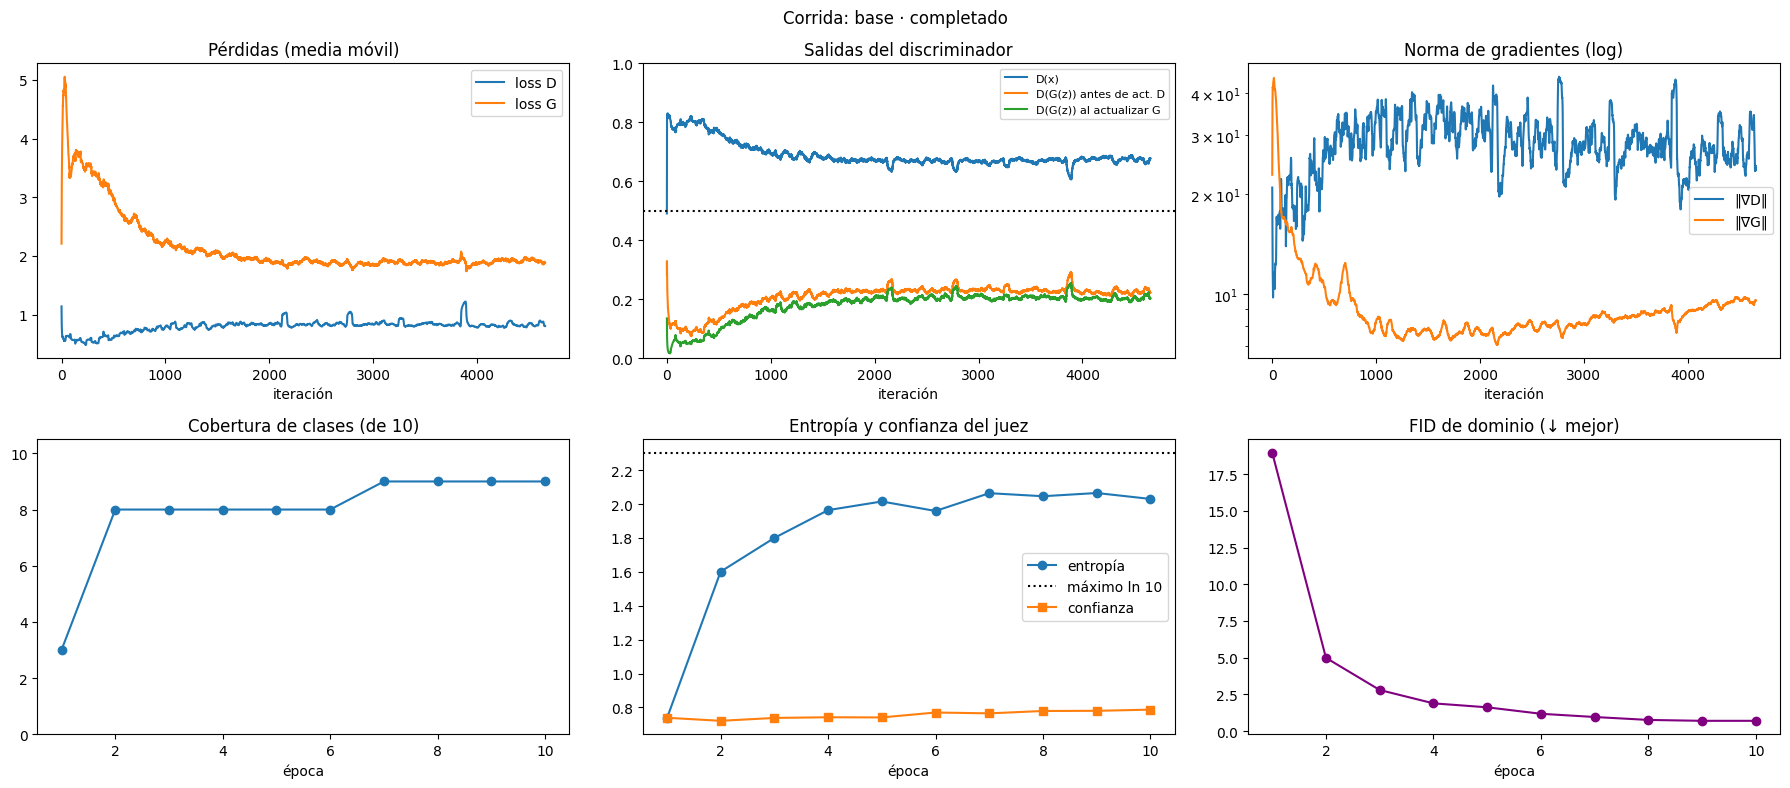

In [11]:
def graficar_corrida(res, suavizar=50):
    r = res["registro"].rolling(suavizar, min_periods=1).mean(); e = res["por_epoca"]
    fig, ax = plt.subplots(2, 3, figsize=(18, 8))
    ax[0, 0].plot(r.it, r.loss_D, label="loss D"); ax[0, 0].plot(r.it, r.loss_G, label="loss G"); ax[0, 0].set_title("Pérdidas (media móvil)"); ax[0, 0].legend()
    ax[0, 1].plot(r.it, r.D_x, label="D(x)"); ax[0, 1].plot(r.it, r.D_Gz_antes, label="D(G(z)) antes de act. D"); ax[0, 1].plot(r.it, r.D_Gz_despues, label="D(G(z)) al actualizar G")
    ax[0, 1].axhline(0.5, c="k", ls=":"); ax[0, 1].set_ylim(0, 1); ax[0, 1].set_title("Salidas del discriminador"); ax[0, 1].legend(fontsize=8)
    ax[0, 2].semilogy(r.it, r.grad_D, label="‖∇D‖"); ax[0, 2].semilogy(r.it, r.grad_G, label="‖∇G‖"); ax[0, 2].set_title("Norma de gradientes (log)"); ax[0, 2].legend()
    if len(e):
        ax[1, 0].plot(e.epoca, e.cobertura, "o-"); ax[1, 0].set(title="Cobertura de clases (de 10)", ylim=(0, 10.5))
        ax[1, 1].plot(e.epoca, e.entropia, "o-", label="entropía"); ax[1, 1].axhline(np.log(10), c="k", ls=":", label="máximo ln 10")
        ax[1, 1].plot(e.epoca, e.confianza, "s-", label="confianza"); ax[1, 1].set_title("Entropía y confianza del juez"); ax[1, 1].legend()
        ax[1, 2].plot(e.epoca, e.fid_dominio, "o-", c="purple"); ax[1, 2].set_title("FID de dominio (↓ mejor)")
    for a in ax[1]: a.set_xlabel("época")
    for a in ax[0]: a.set_xlabel("iteración")
    fig.suptitle(f"Corrida: {res['cfg']['nombre']} · {res['estado']}"); plt.tight_layout()
    plt.savefig(f"curvas_{res['cfg']['nombre']}.png", dpi=110); plt.show()

graficar_corrida(base)

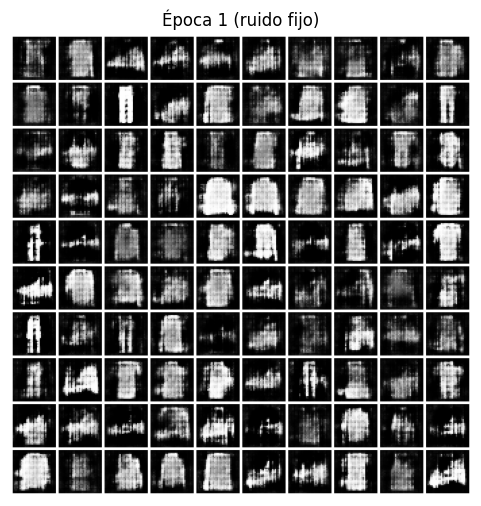

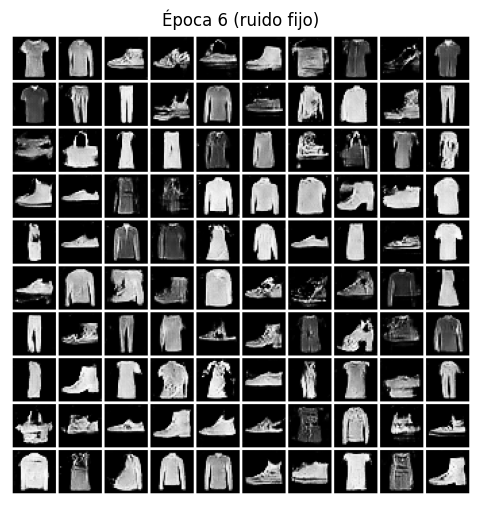

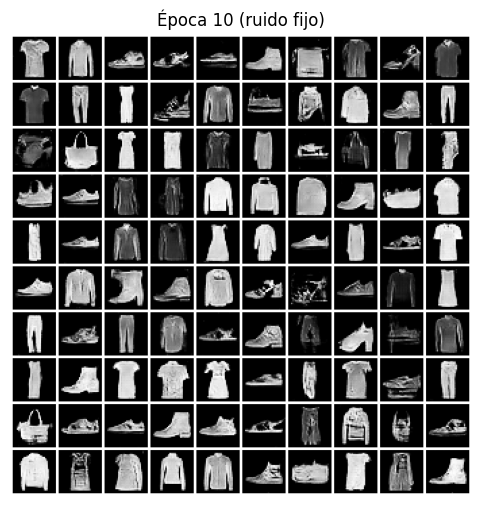

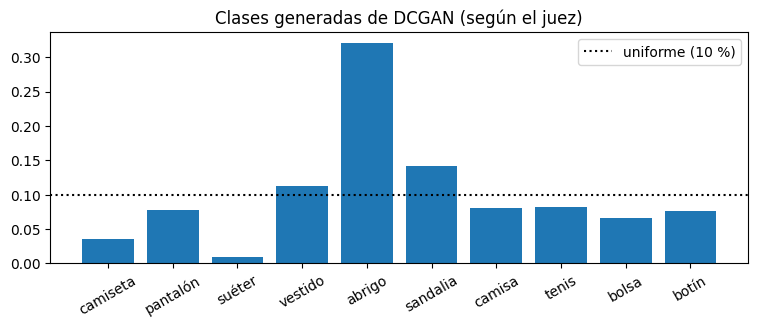

In [12]:
ep_mostrar = sorted(set([0, len(base["rejillas"]) // 2, len(base["rejillas"]) - 1]))
for i in ep_mostrar:
    mostrar_grid(base["rejillas"][i], f"Época {i + 1} (ruido fijo)", tam=(6, 6))

# Distribución de clases según el juez en la última época
frec = base["por_epoca"].iloc[-1].frecuencias
plt.figure(figsize=(9, 3)); plt.bar(CLASES, frec); plt.axhline(0.1, c="k", ls=":", label="uniforme (10 %)")
plt.xticks(rotation=30); plt.title("Clases generadas de DCGAN (según el juez)"); plt.legend(); plt.show()

Describe la dinámica de $D(x)$ y $D(G(z))$ en tu corrida base.

**Al inicio D domina: D(x)≈0.9–1.0, D(G(z))≈0.05–0.15, pero luego se acercan y oscilan: D(x)≈0.65–0.75, D(G(z))≈0.30–0.45.**

¿Llegó a un régimen estable cerca de 0.5?

**No más se acerca, pero D mantiene un ventaja lijera, hay oscilación señal de que el juego sigue activo.**

¿En qué época las muestras se volvieron reconocibles?

**Entre la época 3 y 5, antes de esas son ruido/manchas; después ya se pueden ver las ropa.**

¿Qué clases genera de más y cuáles de menos?

**Mas: Sandalia, tenis, bolso y botín.\
Menos: Camisa, camiseta, suéter y vestido.**

¿Coincide con tu inspección visual?

**Si visualmente destacan los zapatos y bolsos pero las prendas superiores se ven borrosas o híbridas.**

¿Por qué crees que algunas clases (p. ej., *camisa* vs. *camiseta* vs. *suéter*) son más difíciles?

**Por la baja resolución, tienen siluetas muy parecidas, hay pérdida de detalles finos y tendencia de G a generar un como prototipo entre clases.**

## Parte E Diagnóstico automático

La función de abajo aplica **reglas heurísticas** sobre el registro para señalar problemas típicos. Los umbrales son razonables para este notebook, **no universales**: tu trabajo es confirmar o refutar cada alerta con las gráficas y las imágenes.

In [13]:
def diagnosticar(res):
    r, e, alertas = res["registro"], res["por_epoca"], []
    if "DIVERGENCIA" in res["estado"]:
        return ["Divergencia numérica: las pérdidas se volvieron NaN/inf. Típico de LR demasiado alto o sin normalización."]
    cola = r[r.it >= 0.8 * r.it.max()]                         # último 20 % del entrenamiento
    if cola.D_x.mean() > 0.85 and cola.D_Gz_antes.mean() < 0.15:
        alertas.append(f"D domina: D(x)≈{cola.D_x.mean():.2f}, D(G(z))≈{cola.D_Gz_antes.mean():.2f}. "
                       "G recibe poca información útil (riesgo de gradientes que se desvanecen).")
    if cola.D_x.mean() < 0.6 and cola.D_Gz_antes.mean() > 0.4 and cola.loss_D.mean() > 1.3:
        alertas.append("D muy débil: no distingue reales de falsas; G puede 'engañar' sin mejorar la calidad.")
    if len(e):
        ult = e.iloc[-1]
        if ult.cobertura <= 7 or ult.entropia < 1.9:
            alertas.append(f"Posible colapso de modo: cobertura {ult.cobertura}/10, entropía {ult.entropia:.2f} (máx 2.30).")
        if len(e) >= 4 and e.fid_dominio.iloc[-1] > 1.3 * e.fid_dominio.min():
            alertas.append(f"Degradación tardía: el FID de dominio subió de {e.fid_dominio.min():.1f} (mejor) a {e.fid_dominio.iloc[-1]:.1f}.")
        if ult.confianza < 0.6:
            alertas.append(f" Calidad baja: el juez solo tiene {ult.confianza:.2f} de confianza promedio (muestras ambiguas).")
    osc = cola.loss_G.rolling(100).mean().std() / (cola.loss_G.mean() + 1e-9)
    if osc > 0.25:
        alertas.append(f"Oscilación: la pérdida de G varía mucho entre ventanas (coef. de variación {osc:.2f}).")
    return alertas or ["Sin alertas"]

for a in diagnosticar(base): print(a)

Sin alertas


## Parte F Ablación
Define Ablación: **Es como si desactivaras, quitaras o modificaras intencionalmente partes específicas de tu código (como si fueran capas) para medir exactamente cuánto afecta cada componente al rendimiento final del modelo.**

Cada configuración cambia **una sola cosa** respecto a la base y compara. Escribe tu **hipótesis antes** de ejecutar. Selecciona un equipo y responde su pregunta

| Equipo | Variante | Cambio en `CFG` | Pregunta que responde |
|---|---|---|---|
| 1 | Sin BatchNorm | `bn=False` | ¿Qué tanto depende la estabilidad de BN? |
| 2 | Sin inicialización DCGAN | `init_dcgan=False` | ¿Importa N(0, 0.02) frente a la inicialización por defecto de PyTorch? |
| 3 | Sin *label smoothing* | `suavizado=1.0` | ¿D se vuelve demasiado confiado? |
| 4 | LR alto | `lr_G=2e-3, lr_D=2e-3` | ¿Aparece divergencia u oscilación? |
| 5 | D más fuerte | `pasos_D=5` | ¿D domina y G deja de aprender? |
| 6 | Momento de Adam | `beta1=0.9` | ¿Por qué el artículo usa 0.5? |
| 7 | Ruido de instancia | `ruido_instancia=0.1` | ¿Ayuda a estabilizar o solo emborrona? |
| 8 | Ruido latente mínimo | `nz=2` | ¿Un espacio latente pequeño limita la diversidad? |
| 9 | (CIFAR-10) | `dataset="CIFAR10"` en base y variante | ¿Qué cambia con color y fondos complejos? |

#### 1. Sin BatchNorm `bn=False` ¿Qué tanto depende la estabilidad de BN?

Sin BatchNorm, D colapsará y aparecerá divergencia u oscilación graves por que BN es imprescindible.

[sin_BN] ép  1/10  loss_D 0.811  loss_G 2.180  D(x) 0.73  D(G(z)) 0.22→0.17  | cobertura 2/10  entropía 0.62  confianza 0.81  FID-d 90.7  (22 s)
[sin_BN] ép  2/10  loss_D 1.061  loss_G 1.426  D(x) 0.59  D(G(z)) 0.32→0.27  | cobertura 4/10  entropía 0.98  confianza 0.63  FID-d 21.4  (45 s)
[sin_BN] ép  3/10  loss_D 1.006  loss_G 1.519  D(x) 0.61  D(G(z)) 0.29→0.25  | cobertura 6/10  entropía 1.24  confianza 0.72  FID-d 10.8  (68 s)
[sin_BN] ép  4/10  loss_D 0.993  loss_G 1.591  D(x) 0.62  D(G(z)) 0.28→0.24  | cobertura 4/10  entropía 1.17  confianza 0.73  FID-d 12.2  (92 s)
[sin_BN] ép  5/10  loss_D 0.994  loss_G 1.566  D(x) 0.62  D(G(z)) 0.28→0.24  | cobertura 7/10  entropía 1.68  confianza 0.69  FID-d 7.2  (116 s)
[sin_BN] ép  6/10  loss_D 1.012  loss_G 1.484  D(x) 0.61  D(G(z)) 0.29→0.26  | cobertura 7/10  entropía 1.71  confianza 0.70  FID-d 6.6  (140 s)
[sin_BN] ép  7/10  loss_D 1.026  loss_G 1.418  D(x) 0.60  D(G(z)) 0.30→0.28  | cobertura 7/10  entropía 1.68  confianza 0.72  FID-

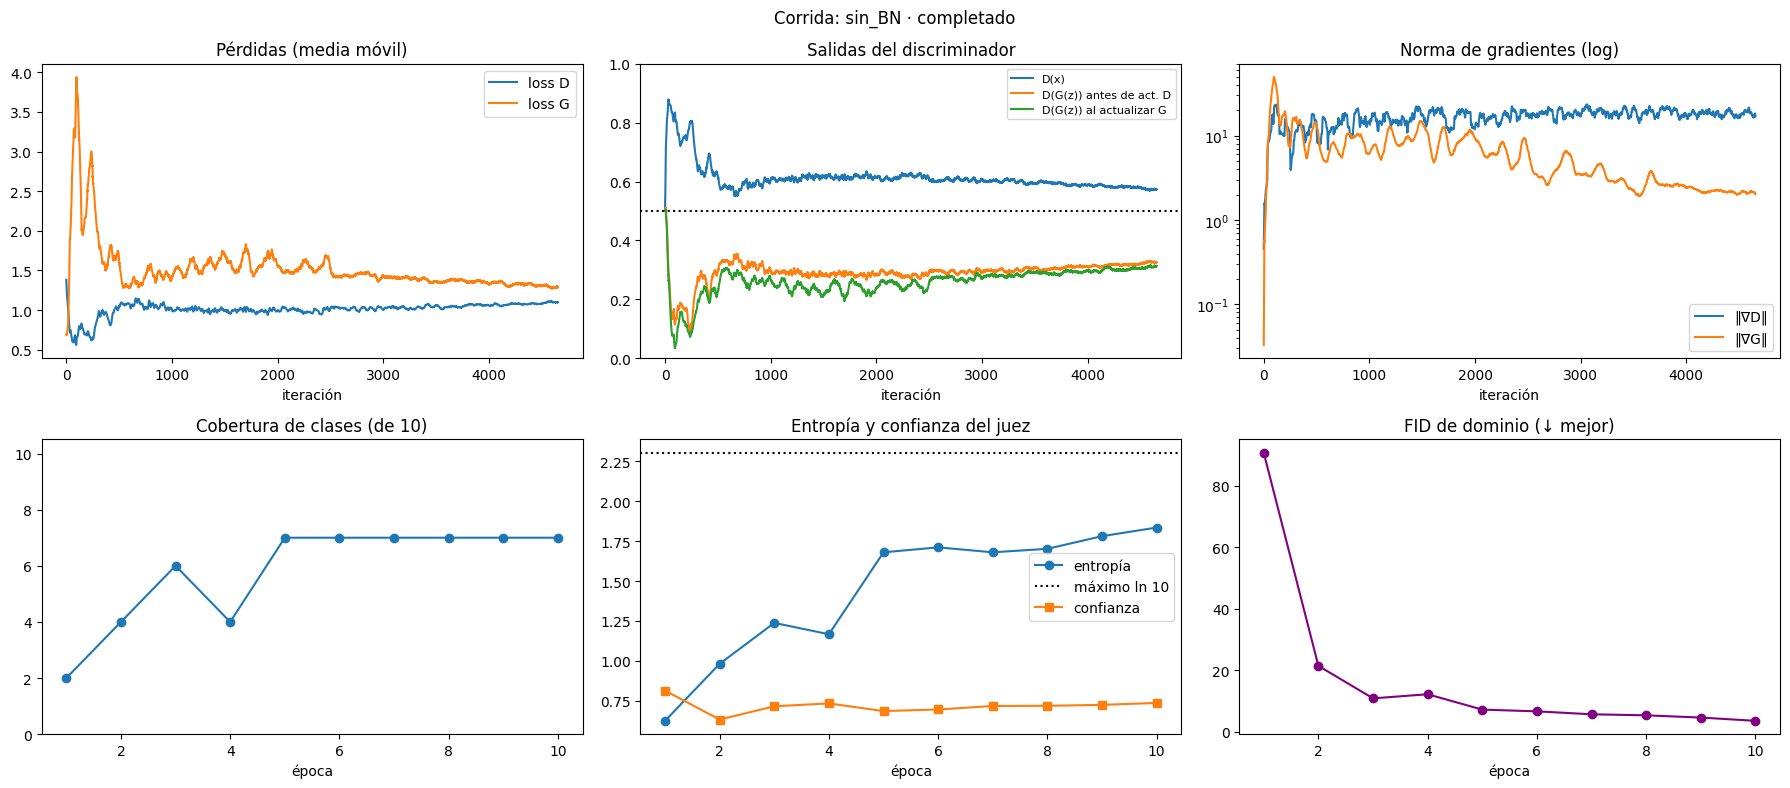

Posible colapso de modo: cobertura 7/10, entropía 1.83 (máx 2.30).


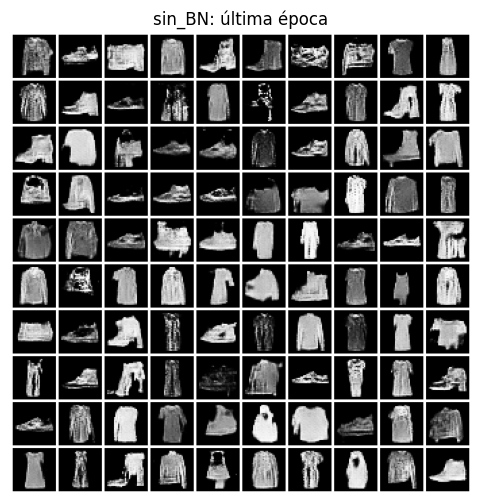

In [18]:
#Ejecutar variantes y comparar
EQUIPO = 1
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,sin_BN,completado,230.1,7,1.835,0.737,3.53,3.53,0.583,0.316,"Posible colapso de modo: cobertura 7/10, entro..."


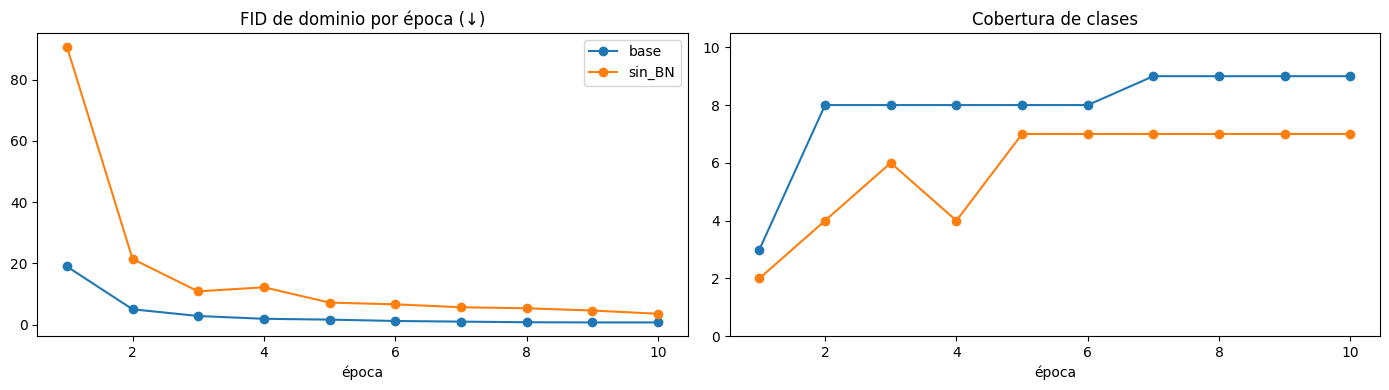

In [19]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 2. Sin inicialización DCGAN `init_dcgan=False` ¿Importa N(0, 0.02) frente a la inicialización por defecto de PyTorch?

Sin init N(0, 0.02), las primeras iteraciones serán inestables pero el modelo tardará más en arrancar, pero puede recuperarse despues.

[sin_init] ép  1/10  loss_D 0.720  loss_G 3.342  D(x) 0.73  D(G(z)) 0.17→0.11  | cobertura 5/10  entropía 1.20  confianza 0.70  FID-d 9.9  (23 s)
[sin_init] ép  2/10  loss_D 0.932  loss_G 1.816  D(x) 0.63  D(G(z)) 0.27→0.21  | cobertura 8/10  entropía 1.71  confianza 0.74  FID-d 3.5  (46 s)
[sin_init] ép  3/10  loss_D 0.982  loss_G 1.645  D(x) 0.61  D(G(z)) 0.29→0.24  | cobertura 8/10  entropía 1.82  confianza 0.76  FID-d 2.6  (69 s)
[sin_init] ép  4/10  loss_D 0.977  loss_G 1.600  D(x) 0.61  D(G(z)) 0.29→0.25  | cobertura 8/10  entropía 1.90  confianza 0.75  FID-d 2.1  (92 s)
[sin_init] ép  5/10  loss_D 0.954  loss_G 1.663  D(x) 0.62  D(G(z)) 0.28→0.24  | cobertura 8/10  entropía 1.99  confianza 0.77  FID-d 1.6  (114 s)
[sin_init] ép  6/10  loss_D 0.929  loss_G 1.680  D(x) 0.63  D(G(z)) 0.27→0.23  | cobertura 9/10  entropía 2.02  confianza 0.76  FID-d 1.2  (137 s)
[sin_init] ép  7/10  loss_D 0.908  loss_G 1.744  D(x) 0.64  D(G(z)) 0.26→0.23  | cobertura 8/10  entropía 1.97  confianza 

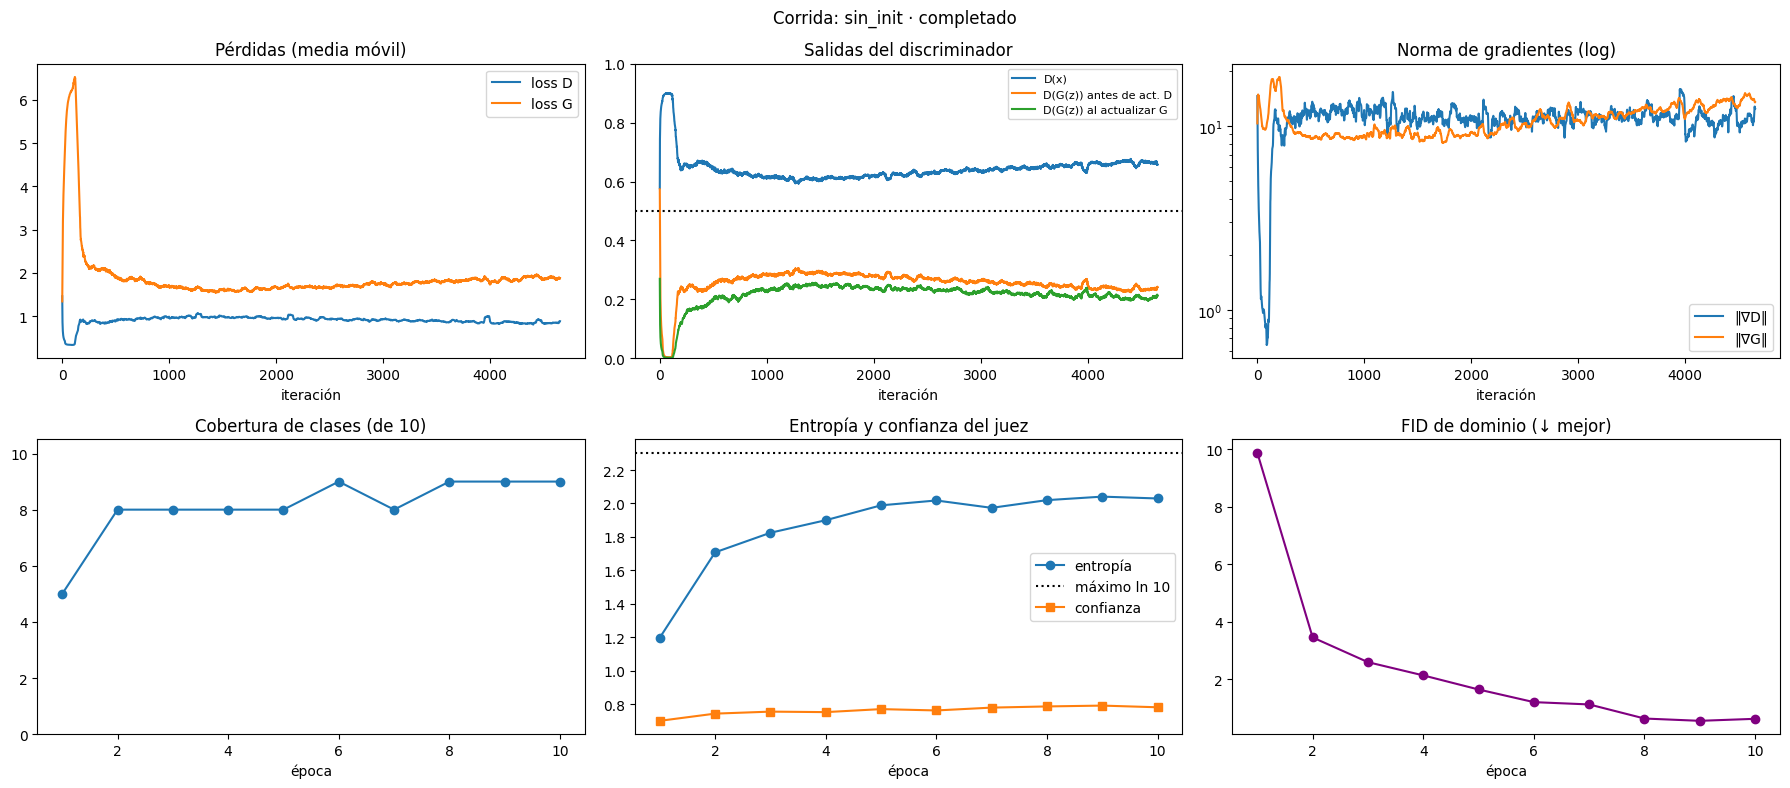

Sin alertas


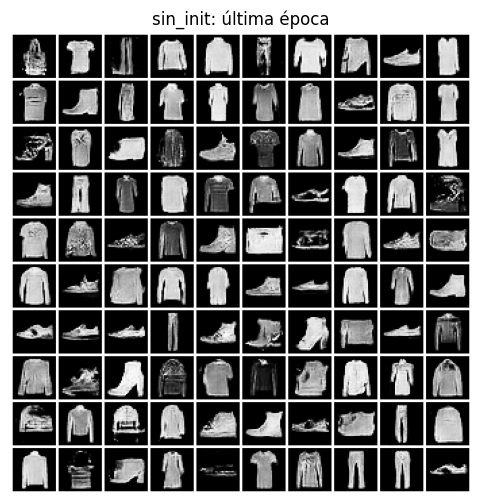

In [20]:
#Ejecutar variantes y comparar
EQUIPO = 2
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.03,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,sin_init,completado,228.5,9,2.03,0.782,0.63,0.56,0.660,0.240,Sin alertas


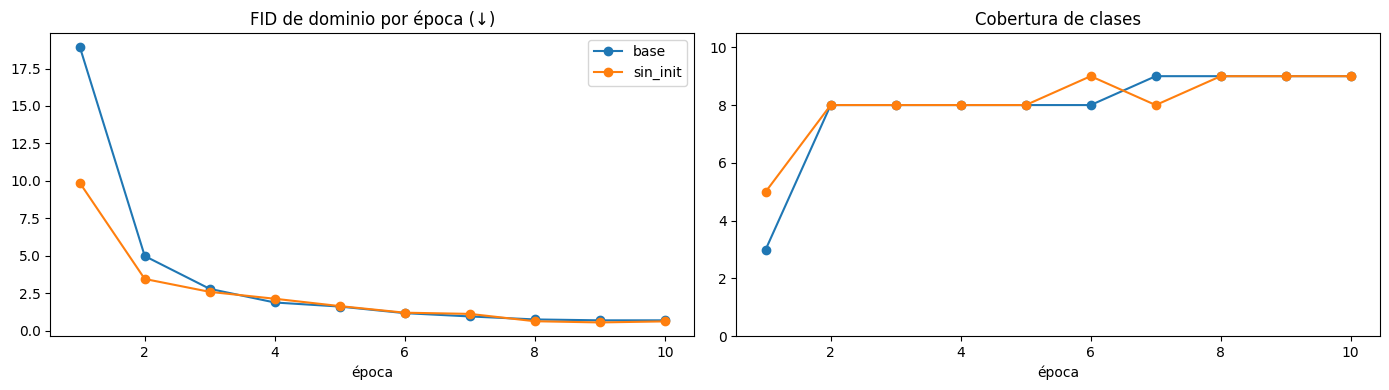

In [21]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 3. Sin *label smoothing* `suavizado=1.0` ¿D se vuelve demasiado confiado?

Sin label smoothing, D se volverá demasiado confiado → D(x) → 1, D(G(z)) → 0, G recibe gradientes débiles.

[sin_suavizado] ép  1/10  loss_D 0.352  loss_G 3.821  D(x) 0.87  D(G(z)) 0.13→0.06  | cobertura 6/10  entropía 1.11  confianza 0.68  FID-d 13.3  (23 s)
[sin_suavizado] ép  2/10  loss_D 0.526  loss_G 2.675  D(x) 0.81  D(G(z)) 0.19→0.14  | cobertura 8/10  entropía 1.67  confianza 0.72  FID-d 3.9  (46 s)
[sin_suavizado] ép  3/10  loss_D 0.656  loss_G 2.132  D(x) 0.76  D(G(z)) 0.24→0.19  | cobertura 8/10  entropía 1.85  confianza 0.73  FID-d 2.7  (69 s)
[sin_suavizado] ép  4/10  loss_D 0.670  loss_G 1.984  D(x) 0.75  D(G(z)) 0.25→0.21  | cobertura 8/10  entropía 1.93  confianza 0.75  FID-d 1.9  (92 s)
[sin_suavizado] ép  5/10  loss_D 0.754  loss_G 1.888  D(x) 0.74  D(G(z)) 0.26→0.23  | cobertura 9/10  entropía 2.00  confianza 0.75  FID-d 1.4  (115 s)
[sin_suavizado] ép  6/10  loss_D 0.686  loss_G 1.868  D(x) 0.74  D(G(z)) 0.25→0.23  | cobertura 8/10  entropía 1.99  confianza 0.77  FID-d 1.0  (137 s)
[sin_suavizado] ép  7/10  loss_D 0.720  loss_G 1.867  D(x) 0.74  D(G(z)) 0.26→0.23  | cober

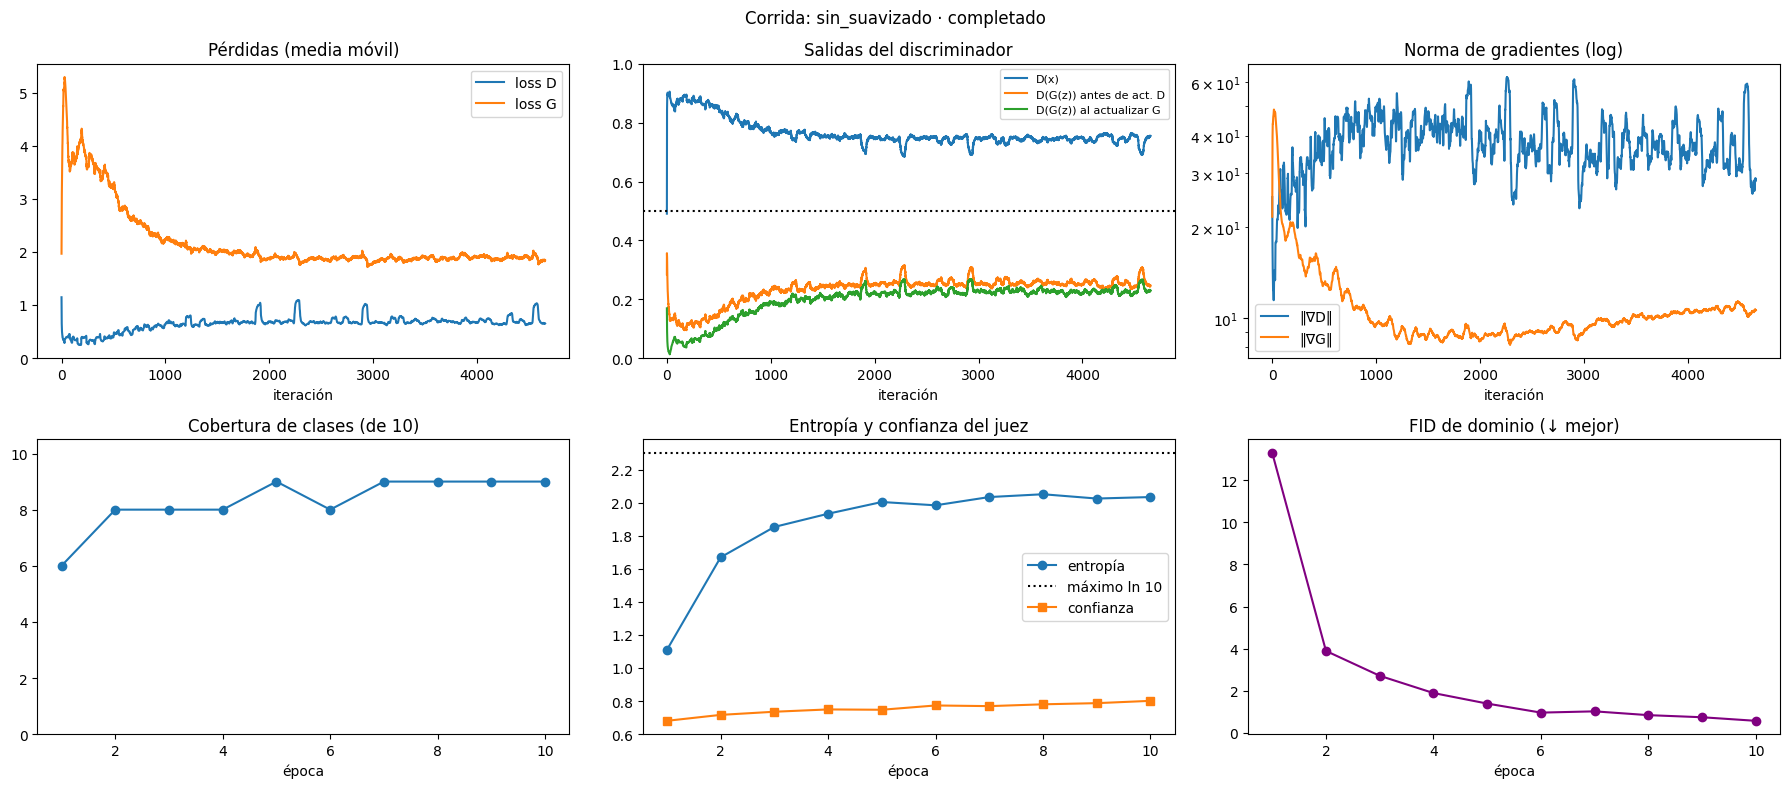

Sin alertas


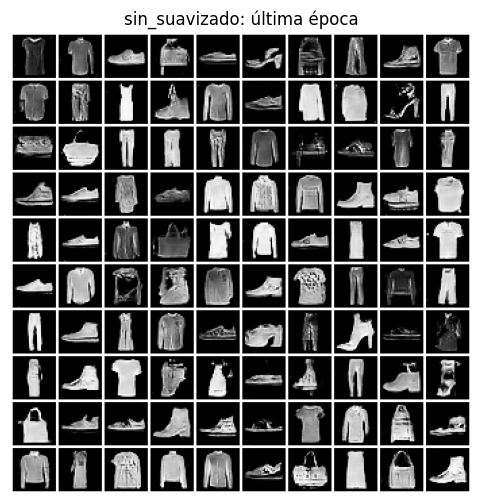

In [22]:
#Ejecutar variantes y comparar
EQUIPO = 3
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,sin_suavizado,completado,228.7,9,2.035,0.801,0.57,0.57,0.744,0.255,Sin alertas


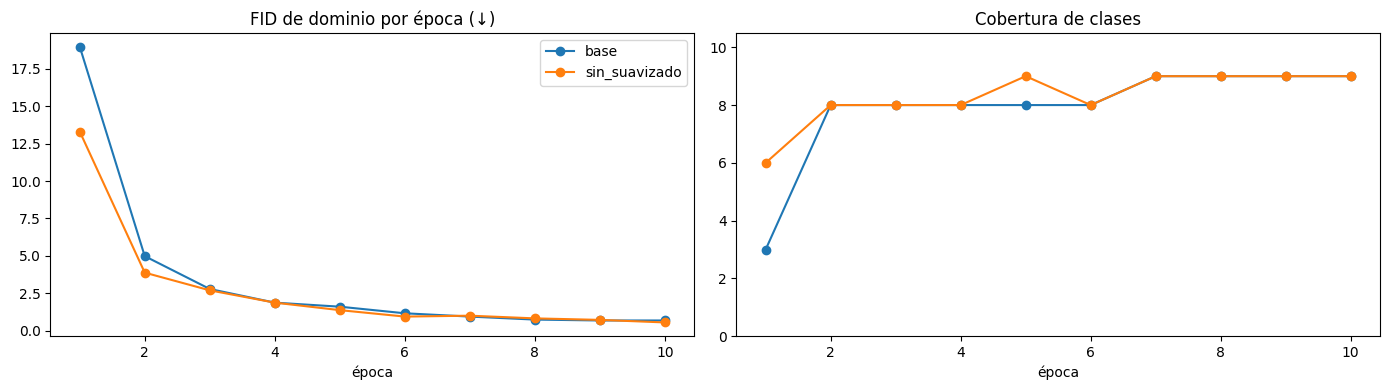

In [23]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 4. LR alto `lr_G=2e-3, lr_D=2e-3` ¿Aparece divergencia u oscilación?

LR 10× más alto = divergencia o pérdidas oscilantes (NaN en el peor caso).

[lr_alto] ép  1/10  loss_D 1.257  loss_G 2.441  D(x) 0.59  D(G(z)) 0.32→0.17  | cobertura 8/10  entropía 1.44  confianza 0.69  FID-d 7.8  (23 s)
[lr_alto] ép  2/10  loss_D 1.180  loss_G 1.847  D(x) 0.57  D(G(z)) 0.33→0.22  | cobertura 8/10  entropía 1.73  confianza 0.76  FID-d 3.0  (46 s)
[lr_alto] ép  3/10  loss_D 1.153  loss_G 1.773  D(x) 0.57  D(G(z)) 0.32→0.23  | cobertura 9/10  entropía 1.97  confianza 0.77  FID-d 1.3  (68 s)
[lr_alto] ép  4/10  loss_D 1.135  loss_G 1.743  D(x) 0.58  D(G(z)) 0.32→0.24  | cobertura 8/10  entropía 1.93  confianza 0.78  FID-d 1.1  (91 s)
[lr_alto] ép  5/10  loss_D 1.104  loss_G 1.743  D(x) 0.59  D(G(z)) 0.31→0.24  | cobertura 8/10  entropía 1.96  confianza 0.78  FID-d 0.9  (114 s)
[lr_alto] ép  6/10  loss_D 1.082  loss_G 1.759  D(x) 0.60  D(G(z)) 0.30→0.24  | cobertura 9/10  entropía 2.05  confianza 0.79  FID-d 0.5  (136 s)
[lr_alto] ép  7/10  loss_D 1.077  loss_G 1.746  D(x) 0.60  D(G(z)) 0.30→0.25  | cobertura 9/10  entropía 2.09  confianza 0.79  F

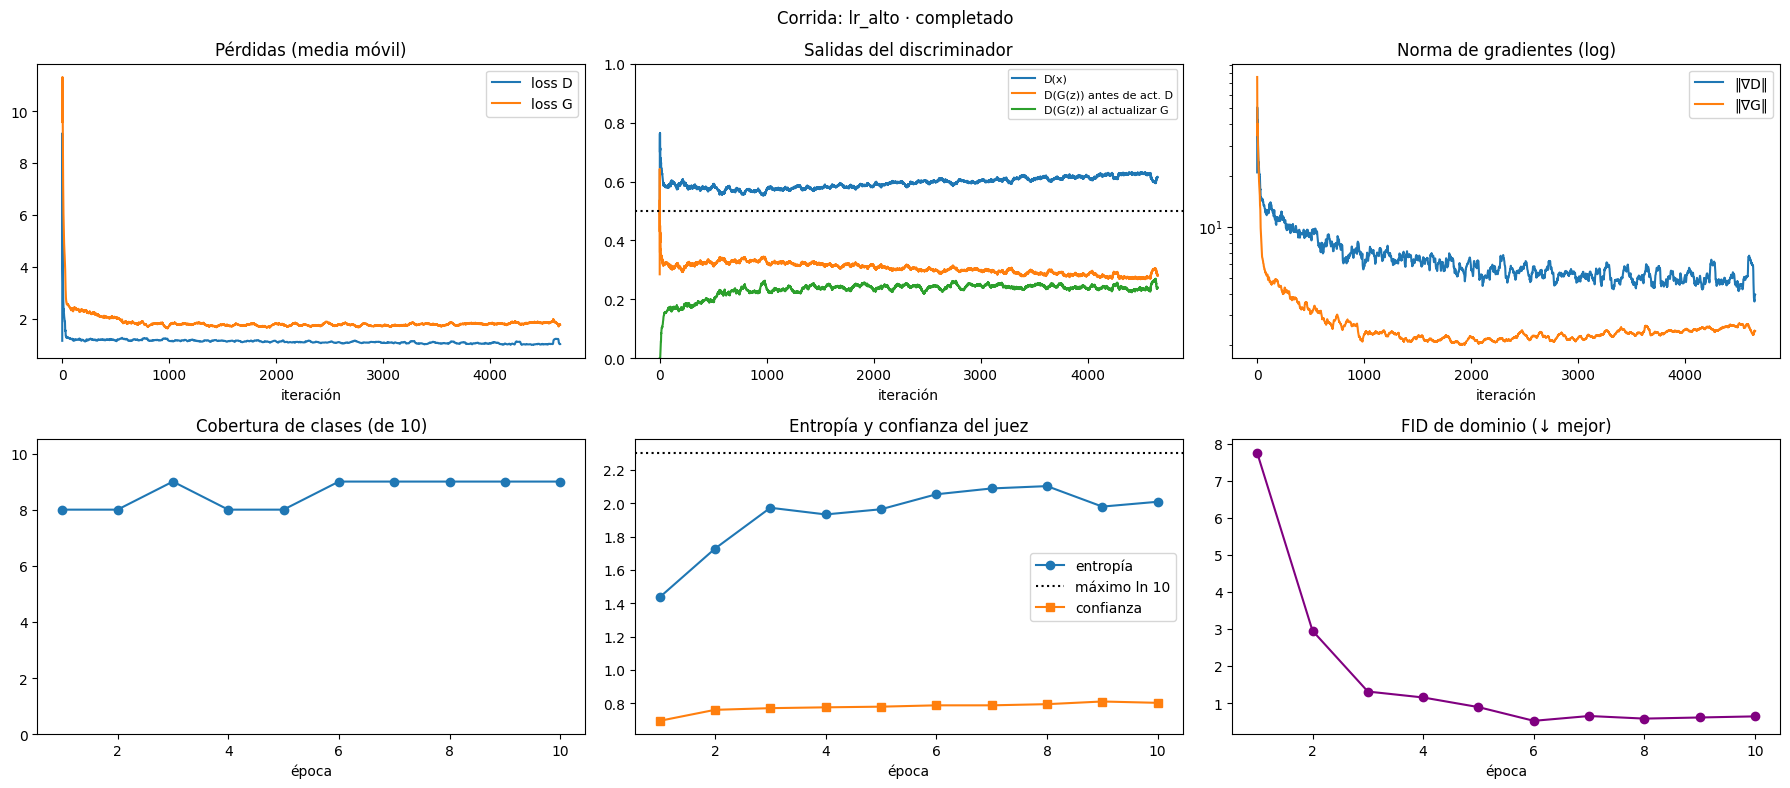

Sin alertas


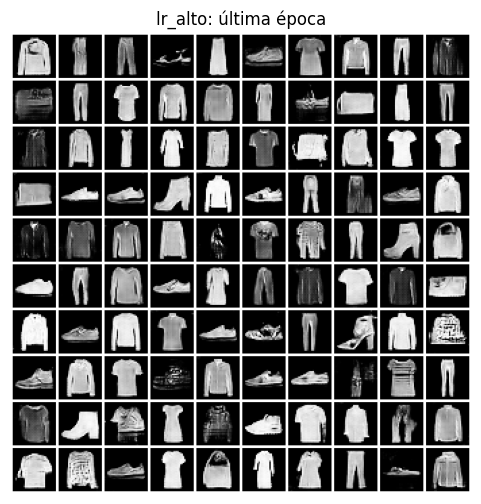

In [24]:
#Ejecutar variantes y comparar
EQUIPO = 4
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,lr_alto,completado,227.3,9,2.009,0.802,0.64,0.52,0.619,0.281,Sin alertas


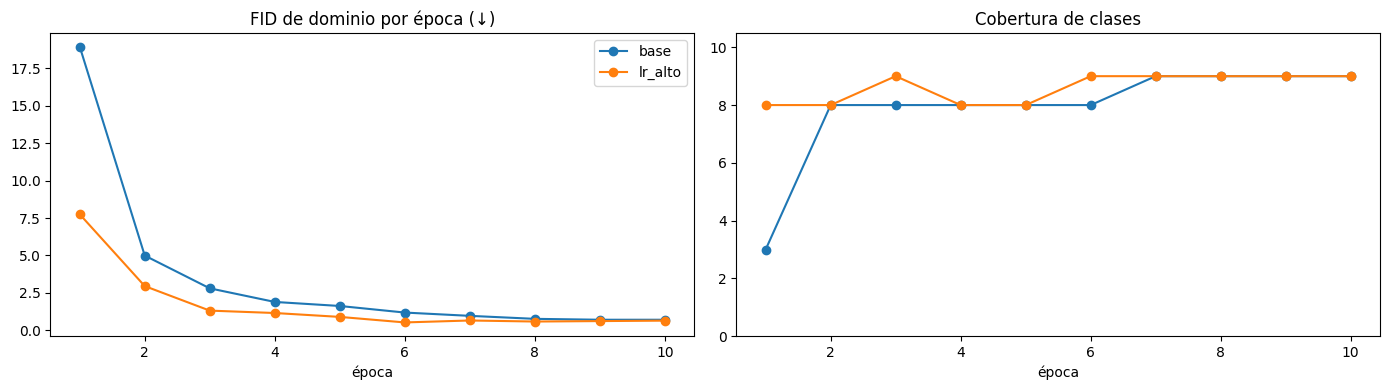

In [25]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 5. D más fuerte `pasos_D=5` ¿D domina y G deja de aprender?

D se entrena 5× por paso de G → D domina y G no aprende.

[D_5pasos] ép  1/10  loss_D 0.376  loss_G 5.773  D(x) 0.88  D(G(z)) 0.01→0.01  | cobertura 3/10  entropía 0.57  confianza 0.78  FID-d 18.5  (72 s)
[D_5pasos] ép  2/10  loss_D 0.376  loss_G 5.220  D(x) 0.88  D(G(z)) 0.01→0.01  | cobertura 7/10  entropía 1.48  confianza 0.73  FID-d 5.0  (144 s)
[D_5pasos] ép  3/10  loss_D 0.383  loss_G 4.891  D(x) 0.87  D(G(z)) 0.02→0.02  | cobertura 8/10  entropía 1.82  confianza 0.72  FID-d 3.1  (216 s)
[D_5pasos] ép  4/10  loss_D 0.375  loss_G 4.735  D(x) 0.89  D(G(z)) 0.02→0.02  | cobertura 8/10  entropía 1.93  confianza 0.74  FID-d 1.9  (288 s)
[D_5pasos] ép  5/10  loss_D 0.381  loss_G 4.537  D(x) 0.89  D(G(z)) 0.03→0.02  | cobertura 8/10  entropía 2.01  confianza 0.75  FID-d 1.4  (360 s)
[D_5pasos] ép  6/10  loss_D 0.393  loss_G 4.353  D(x) 0.89  D(G(z)) 0.03→0.03  | cobertura 9/10  entropía 2.03  confianza 0.77  FID-d 0.9  (433 s)
[D_5pasos] ép  7/10  loss_D 0.379  loss_G 4.433  D(x) 0.89  D(G(z)) 0.03→0.02  | cobertura 8/10  entropía 2.03  confia

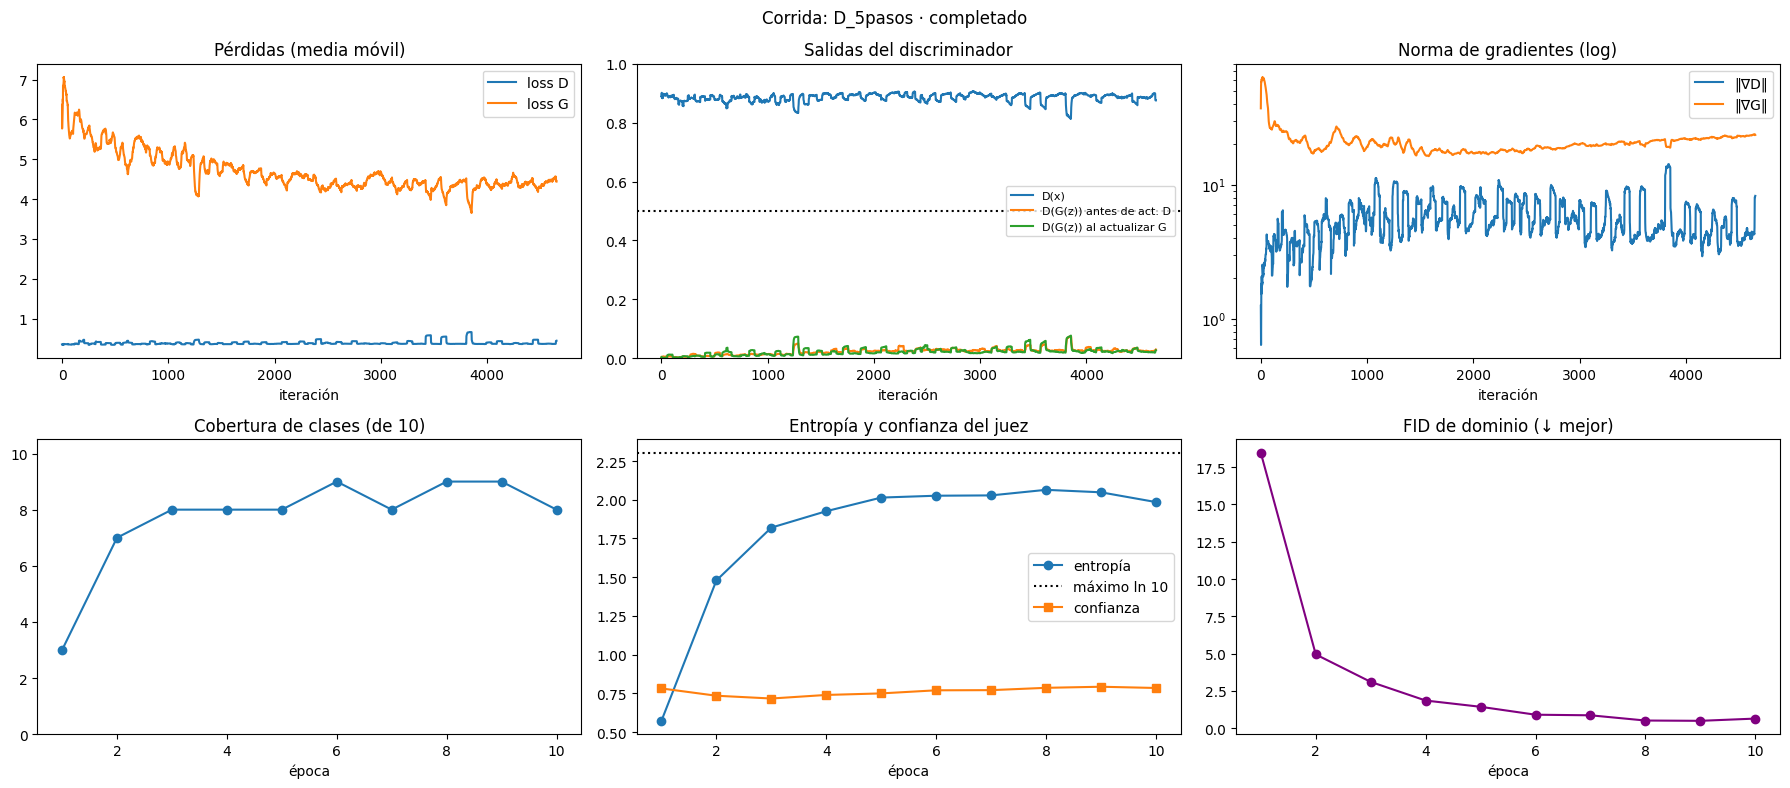

D domina: D(x)≈0.88, D(G(z))≈0.03. G recibe poca información útil (riesgo de gradientes que se desvanecen).


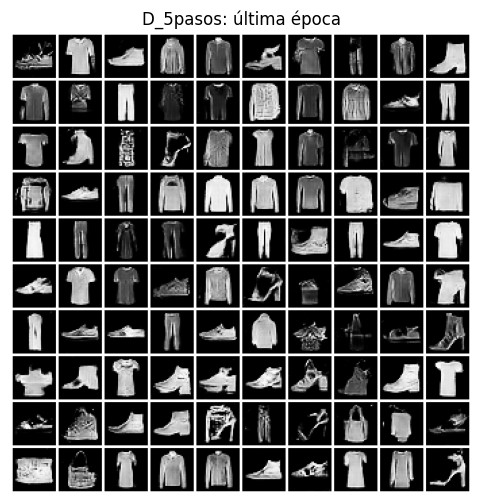

In [26]:
#Ejecutar variantes y comparar
EQUIPO = 5
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.7,0.671,0.228,Sin alertas
1,D_5pasos,completado,727.0,8,1.985,0.785,0.65,0.5,0.884,0.030,"D domina: D(x)≈0.88, D(G(z))≈0.03. G recibe po..."


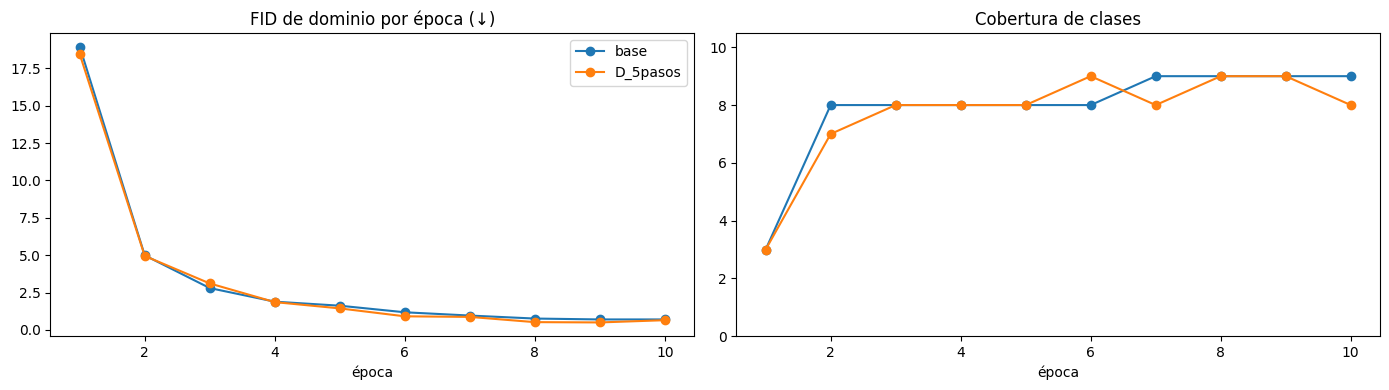

In [27]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 6. Momento de Adam `beta1=0.9` ¿Por qué el artículo usa 0.5?

Con más momento el entrenamiento es más inestable, β₁=0.5 reduce la inercia del optimizador.

[beta1_0.9] ép  1/10  loss_D 0.391  loss_G 5.395  D(x) 0.88  D(G(z)) 0.03→0.01  | cobertura 2/10  entropía 0.72  confianza 0.69  FID-d 30.7  (23 s)
[beta1_0.9] ép  2/10  loss_D 0.374  loss_G 5.150  D(x) 0.88  D(G(z)) 0.02→0.01  | cobertura 3/10  entropía 1.02  confianza 0.70  FID-d 21.6  (47 s)
[beta1_0.9] ép  3/10  loss_D 0.379  loss_G 4.955  D(x) 0.88  D(G(z)) 0.02→0.01  | cobertura 4/10  entropía 1.26  confianza 0.68  FID-d 16.8  (70 s)
[beta1_0.9] ép  4/10  loss_D 0.385  loss_G 4.993  D(x) 0.88  D(G(z)) 0.02→0.01  | cobertura 7/10  entropía 1.63  confianza 0.64  FID-d 8.6  (92 s)
[beta1_0.9] ép  5/10  loss_D 0.402  loss_G 4.754  D(x) 0.87  D(G(z)) 0.03→0.02  | cobertura 5/10  entropía 0.94  confianza 0.80  FID-d 9.0  (115 s)
[beta1_0.9] ép  6/10  loss_D 0.406  loss_G 4.726  D(x) 0.87  D(G(z)) 0.03→0.02  | cobertura 8/10  entropía 1.50  confianza 0.70  FID-d 6.8  (139 s)
[beta1_0.9] ép  7/10  loss_D 0.424  loss_G 4.459  D(x) 0.86  D(G(z)) 0.04→0.02  | cobertura 7/10  entropía 1.69  

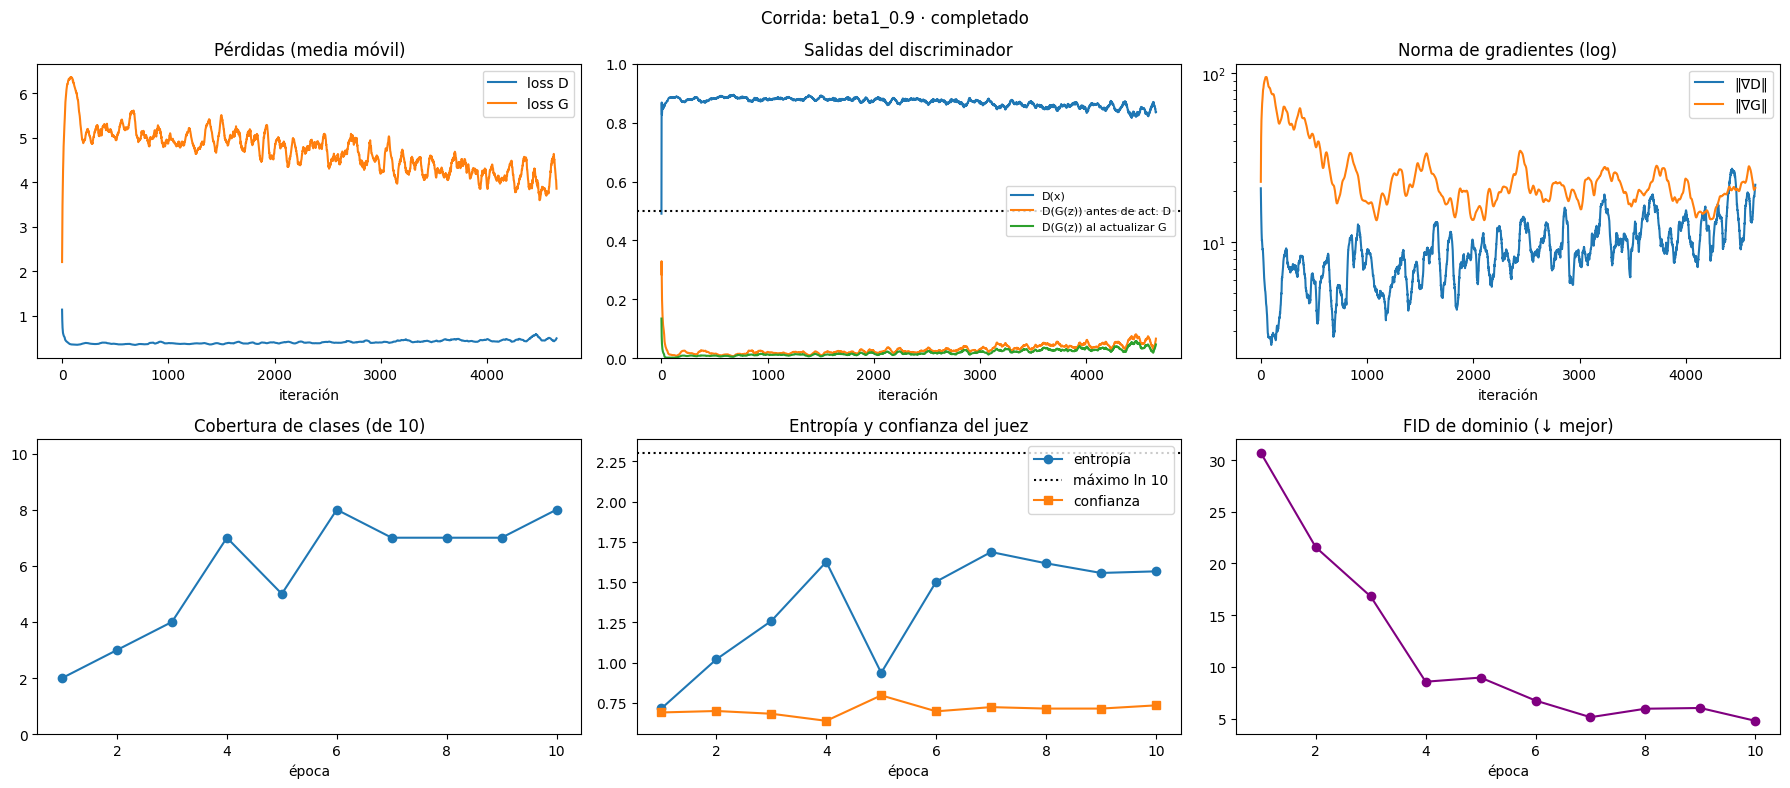

Posible colapso de modo: cobertura 8/10, entropía 1.57 (máx 2.30).


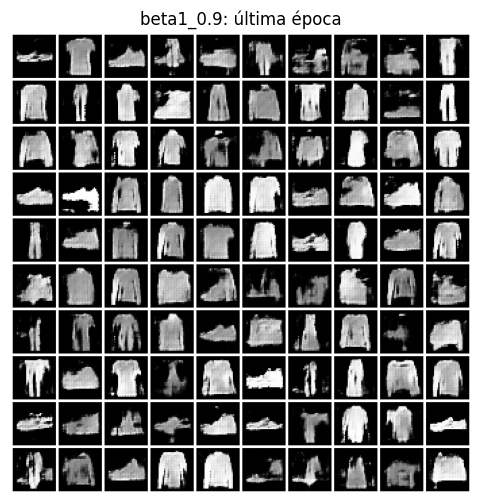

In [28]:
#Ejecutar variantes y comparar
EQUIPO = 6
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,beta1_0.9,completado,232.0,8,1.567,0.735,4.79,4.79,0.849,0.050,"Posible colapso de modo: cobertura 8/10, entro..."


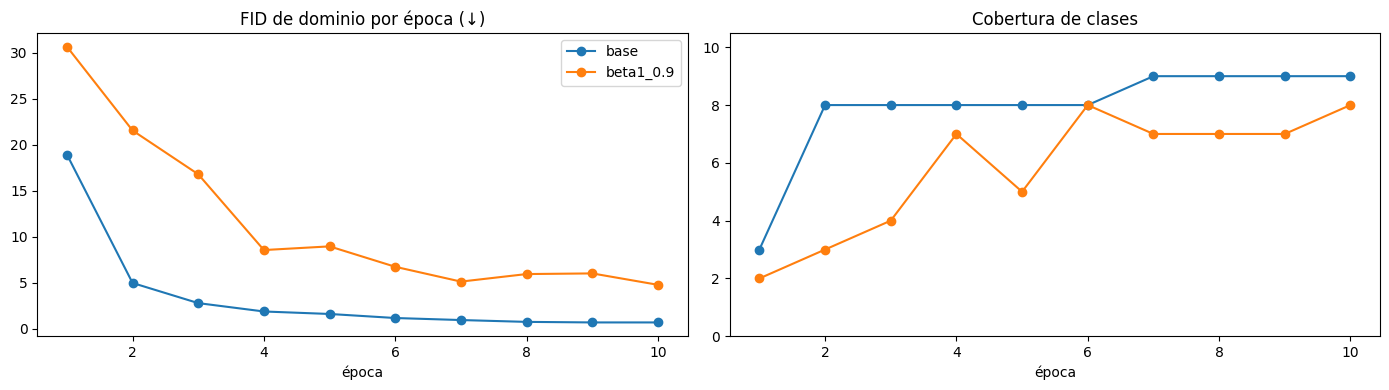

In [29]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 7. Ruido de instancia `ruido_instancia=0.1` ¿Ayuda a estabilizar o solo emborrona?

El ruido gaussiano en las entradas de D regulariza al discriminador, evitando que se vuelva demasiado confiado, espero D(x) y D(G(z)) más cerca de 0.5, loss_D más alta al inicio, y mejor cobertura (menos colapso) a costa de una ligera caída en confianza/FID.

[ruido_instancia] ép  1/10  loss_D 0.599  loss_G 3.398  D(x) 0.78  D(G(z)) 0.12→0.07  | cobertura 6/10  entropía 1.12  confianza 0.69  FID-d 11.9  (23 s)
[ruido_instancia] ép  2/10  loss_D 0.758  loss_G 2.413  D(x) 0.71  D(G(z)) 0.19→0.14  | cobertura 8/10  entropía 1.69  confianza 0.72  FID-d 4.7  (47 s)
[ruido_instancia] ép  3/10  loss_D 0.829  loss_G 2.033  D(x) 0.68  D(G(z)) 0.22→0.19  | cobertura 8/10  entropía 1.85  confianza 0.74  FID-d 2.7  (70 s)
[ruido_instancia] ép  4/10  loss_D 0.864  loss_G 1.969  D(x) 0.66  D(G(z)) 0.24→0.19  | cobertura 8/10  entropía 1.84  confianza 0.76  FID-d 2.4  (93 s)
[ruido_instancia] ép  5/10  loss_D 0.871  loss_G 1.909  D(x) 0.66  D(G(z)) 0.24→0.20  | cobertura 8/10  entropía 1.92  confianza 0.76  FID-d 1.4  (116 s)
[ruido_instancia] ép  6/10  loss_D 0.843  loss_G 1.907  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 1.96  confianza 0.77  FID-d 1.4  (139 s)
[ruido_instancia] ép  7/10  loss_D 0.845  loss_G 1.875  D(x) 0.67  D(G(z)) 0.23

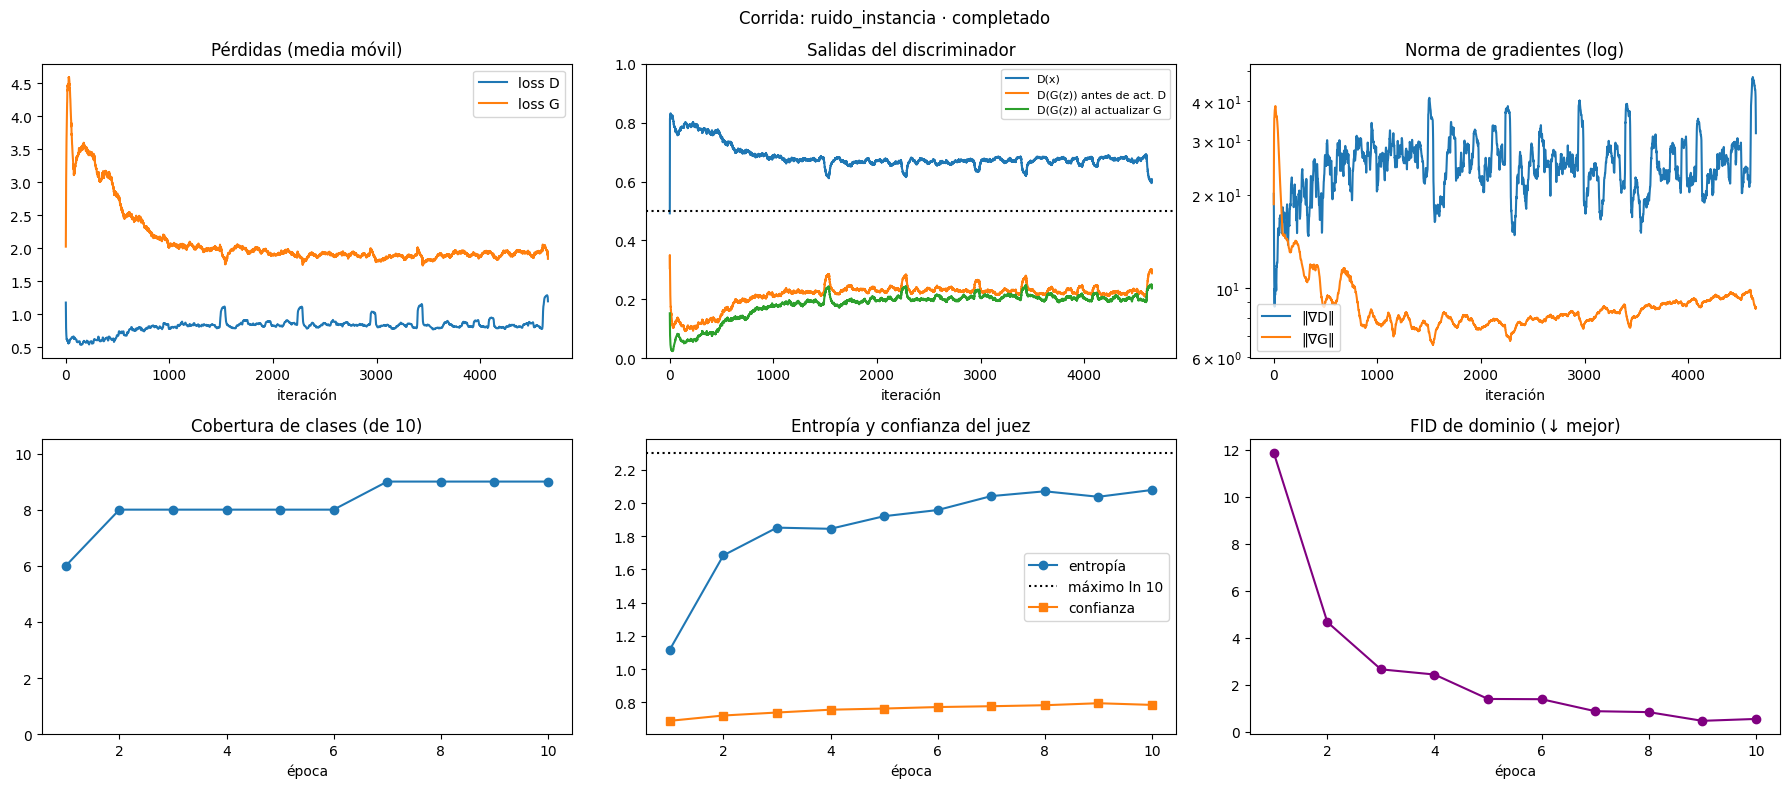

Sin alertas


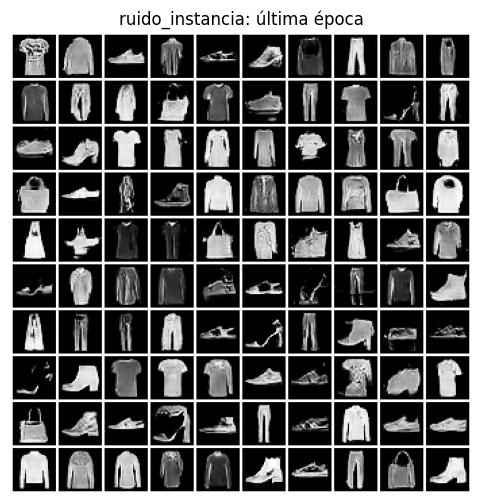

In [30]:
#Ejecutar variantes y comparar
EQUIPO = 7
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,ruido_instancia,completado,230.4,9,2.079,0.784,0.55,0.47,0.670,0.229,Sin alertas


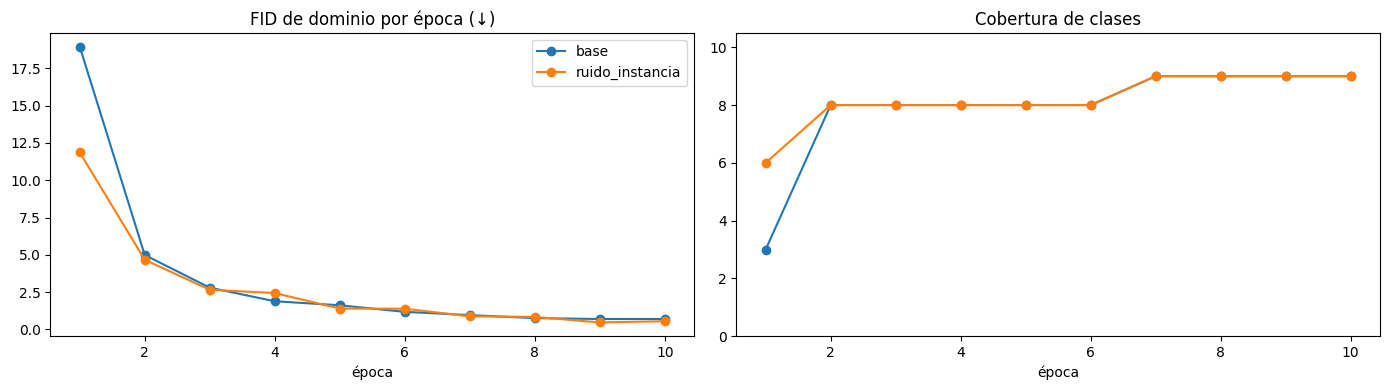

In [31]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 8. Ruido latente mínimo `nz=2` ¿Un espacio latente pequeño limita la diversidad?

Espacio latente minúsculo = colapso de modo evidente, diversidad limitada.

[nz_2] ép  1/10  loss_D 0.833  loss_G 2.786  D(x) 0.70  D(G(z)) 0.21→0.10  | cobertura 5/10  entropía 1.16  confianza 0.66  FID-d 12.6  (22 s)
[nz_2] ép  2/10  loss_D 0.793  loss_G 2.674  D(x) 0.70  D(G(z)) 0.20→0.10  | cobertura 5/10  entropía 1.50  confianza 0.67  FID-d 11.0  (44 s)
[nz_2] ép  3/10  loss_D 0.755  loss_G 2.760  D(x) 0.72  D(G(z)) 0.18→0.09  | cobertura 7/10  entropía 1.52  confianza 0.72  FID-d 7.1  (66 s)
[nz_2] ép  4/10  loss_D 0.738  loss_G 2.783  D(x) 0.73  D(G(z)) 0.17→0.09  | cobertura 6/10  entropía 1.49  confianza 0.76  FID-d 8.7  (88 s)
[nz_2] ép  5/10  loss_D 0.734  loss_G 2.821  D(x) 0.73  D(G(z)) 0.17→0.09  | cobertura 7/10  entropía 1.57  confianza 0.76  FID-d 5.5  (110 s)
[nz_2] ép  6/10  loss_D 0.723  loss_G 2.821  D(x) 0.73  D(G(z)) 0.17→0.09  | cobertura 6/10  entropía 1.64  confianza 0.73  FID-d 5.8  (131 s)
[nz_2] ép  7/10  loss_D 0.734  loss_G 2.786  D(x) 0.73  D(G(z)) 0.17→0.10  | cobertura 8/10  entropía 2.07  confianza 0.77  FID-d 3.0  (153 s)
[

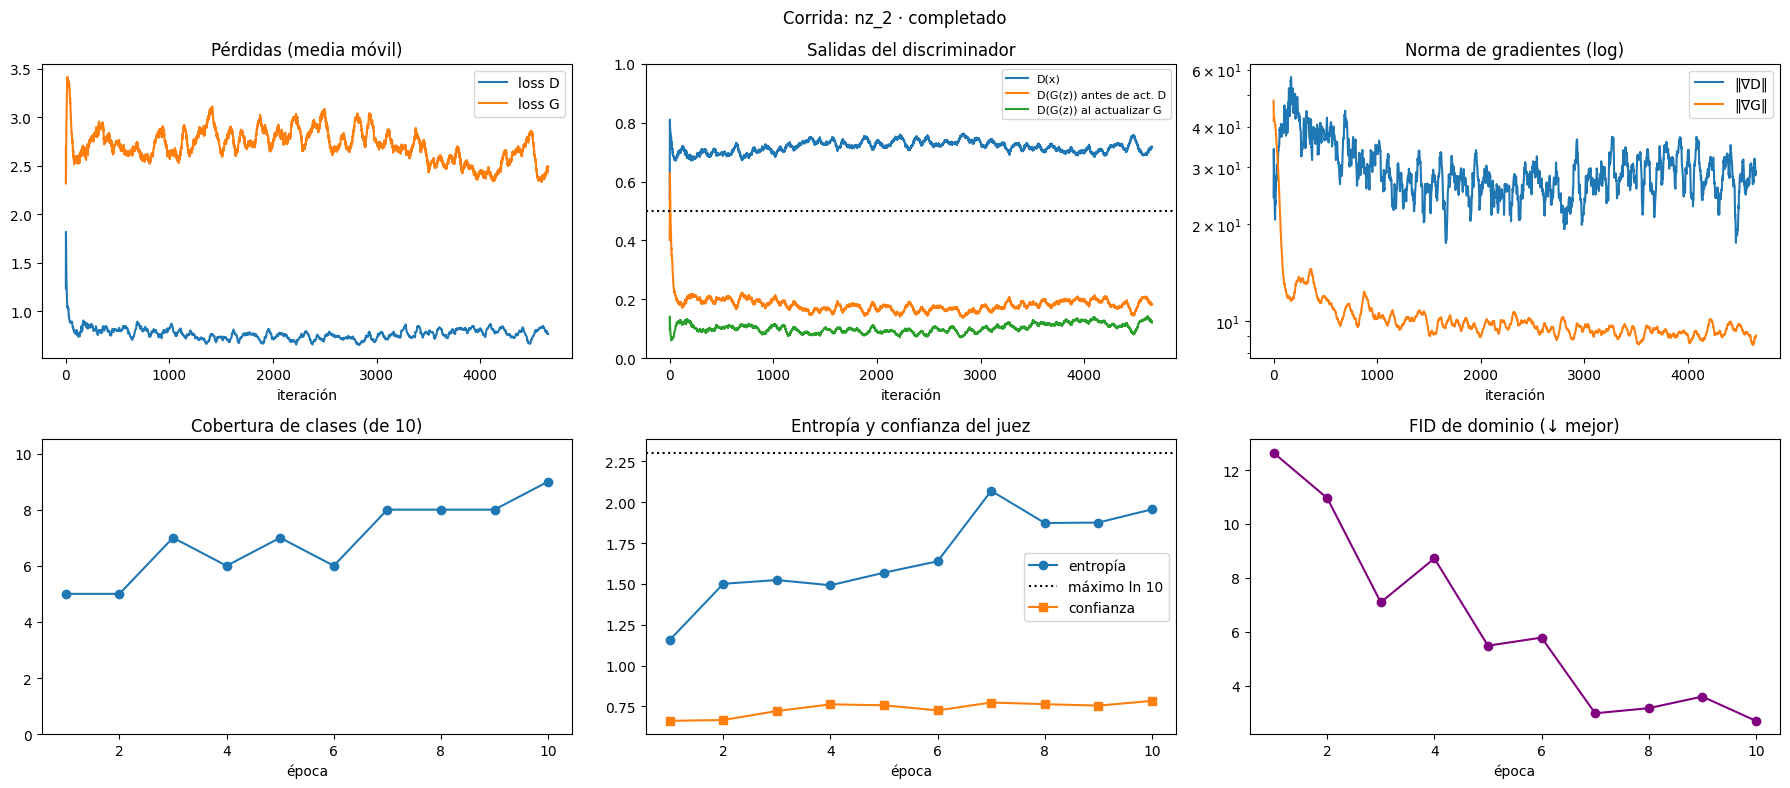

Sin alertas


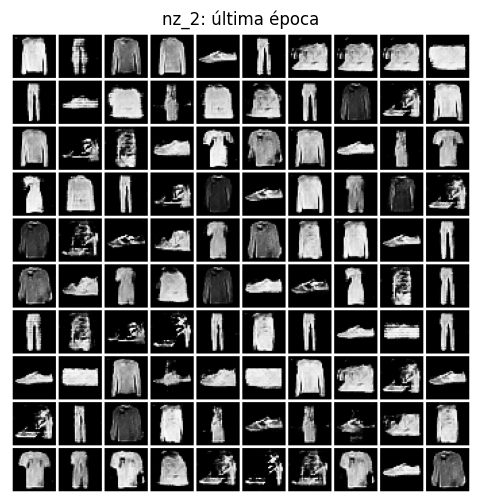

In [32]:
#Ejecutar variantes y comparar
EQUIPO = 8
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,nz_2,completado,219.0,9,1.957,0.784,2.69,2.69,0.709,0.190,Sin alertas


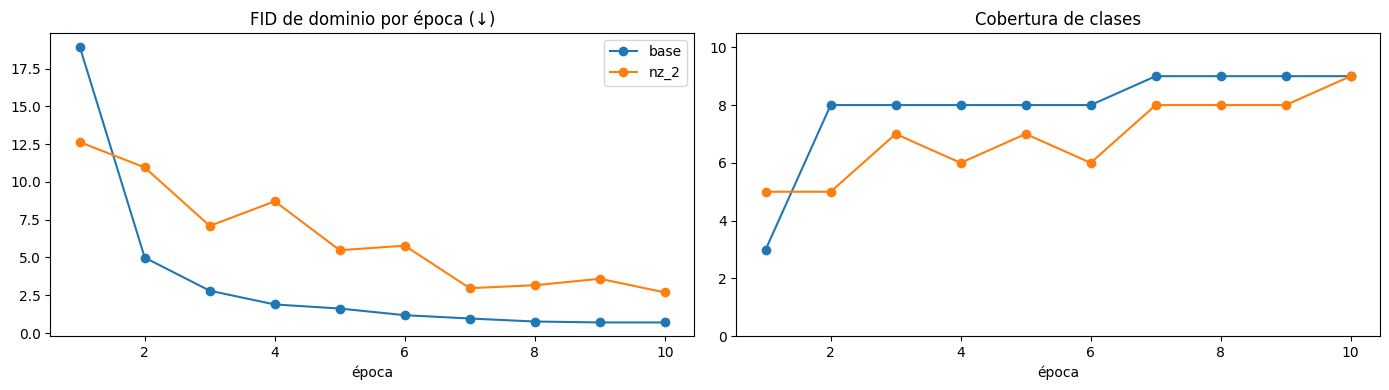

In [33]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### 9. (CIFAR-10) `dataset="CIFAR10"` en base y variante ¿Qué cambia con color y fondos complejos?

Fondos complejos y color = más difícil, FID sube mucho, aparece más ruido de alta frecuencia.

[cifar_variante] ép  1/10  loss_D 0.581  loss_G 3.543  D(x) 0.79  D(G(z)) 0.11→0.06  | cobertura 5/10  entropía 0.98  confianza 0.68  FID-d 12.7  (23 s)
[cifar_variante] ép  2/10  loss_D 0.715  loss_G 2.570  D(x) 0.73  D(G(z)) 0.17→0.13  | cobertura 8/10  entropía 1.58  confianza 0.72  FID-d 4.5  (46 s)
[cifar_variante] ép  3/10  loss_D 0.793  loss_G 2.145  D(x) 0.69  D(G(z)) 0.21→0.17  | cobertura 8/10  entropía 1.82  confianza 0.74  FID-d 2.9  (69 s)
[cifar_variante] ép  4/10  loss_D 0.833  loss_G 2.000  D(x) 0.68  D(G(z)) 0.22→0.19  | cobertura 8/10  entropía 1.92  confianza 0.75  FID-d 2.0  (92 s)
[cifar_variante] ép  5/10  loss_D 0.847  loss_G 1.923  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 1.98  confianza 0.76  FID-d 1.4  (115 s)
[cifar_variante] ép  6/10  loss_D 0.838  loss_G 1.909  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 2.00  confianza 0.76  FID-d 1.4  (137 s)
[cifar_variante] ép  7/10  loss_D 0.829  loss_G 1.905  D(x) 0.67  D(G(z)) 0.23→0.20  

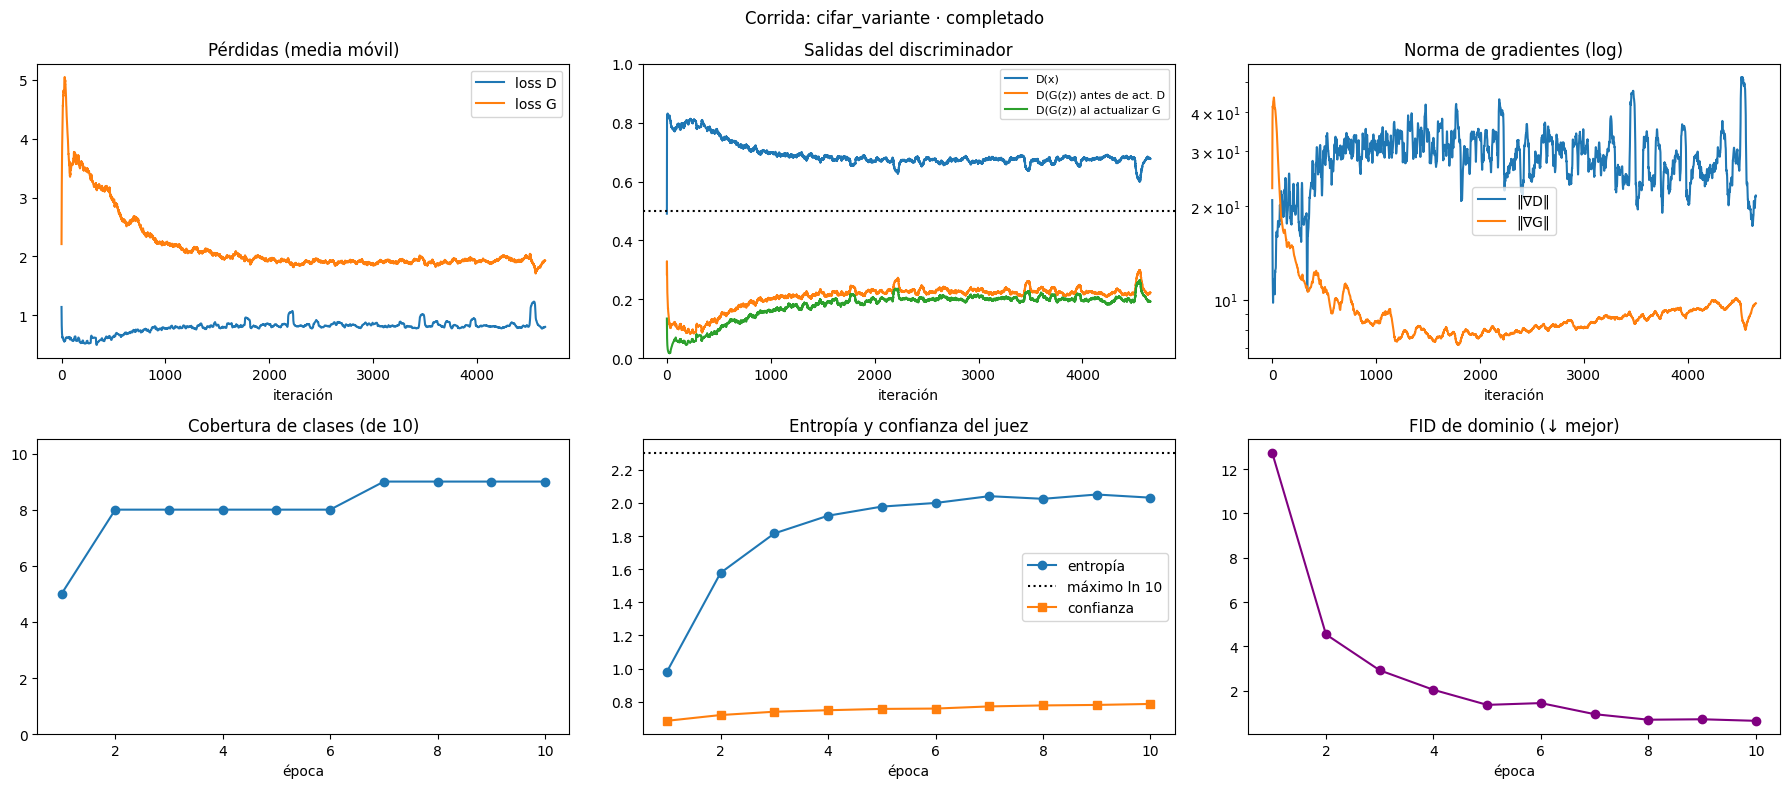

Sin alertas


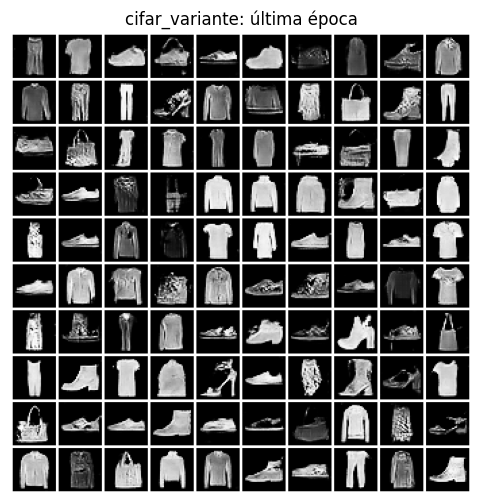

In [34]:
#Ejecutar variantes y comparar
EQUIPO = 9
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.030,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,cifar_variante,completado,229.0,9,2.032,0.786,0.64,0.64,0.673,0.227,Sin alertas


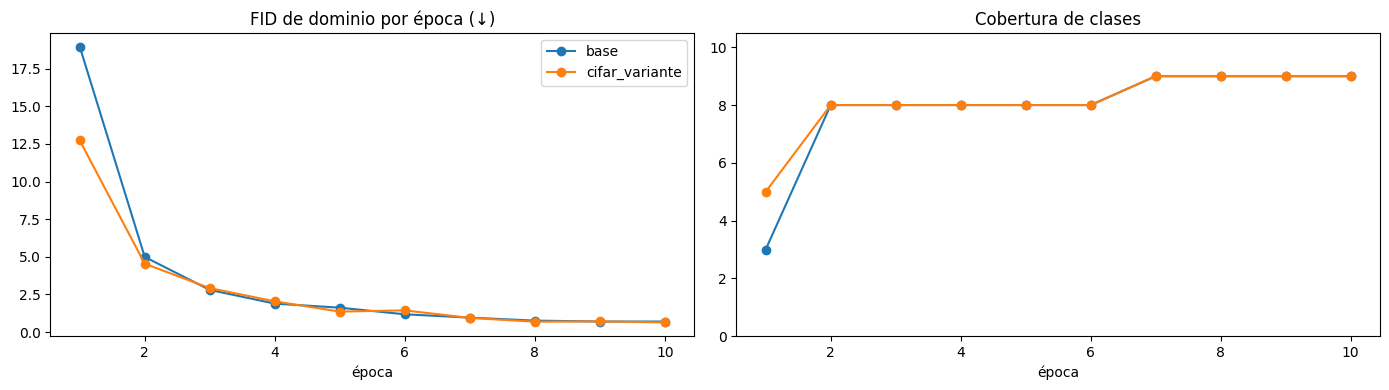

In [35]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

#### Ejemplo hecho en clase

[ruido_instancia] ép  1/10  loss_D 0.602  loss_G 3.405  D(x) 0.78  D(G(z)) 0.12→0.07  | cobertura 3/10  entropía 0.62  confianza 0.77  FID-d 14.6  (23 s)
[ruido_instancia] ép  2/10  loss_D 0.747  loss_G 2.485  D(x) 0.71  D(G(z)) 0.18→0.14  | cobertura 8/10  entropía 1.54  confianza 0.75  FID-d 4.7  (46 s)
[ruido_instancia] ép  3/10  loss_D 0.820  loss_G 2.065  D(x) 0.68  D(G(z)) 0.22→0.18  | cobertura 8/10  entropía 1.76  confianza 0.74  FID-d 3.1  (69 s)
[ruido_instancia] ép  4/10  loss_D 0.861  loss_G 1.955  D(x) 0.66  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 1.91  confianza 0.76  FID-d 1.9  (92 s)
[ruido_instancia] ép  5/10  loss_D 0.855  loss_G 1.914  D(x) 0.66  D(G(z)) 0.24→0.20  | cobertura 8/10  entropía 1.94  confianza 0.76  FID-d 1.3  (115 s)
[ruido_instancia] ép  6/10  loss_D 0.862  loss_G 1.877  D(x) 0.66  D(G(z)) 0.24→0.21  | cobertura 8/10  entropía 2.01  confianza 0.77  FID-d 1.1  (137 s)
[ruido_instancia] ép  7/10  loss_D 0.846  loss_G 1.892  D(x) 0.67  D(G(z)) 0.23

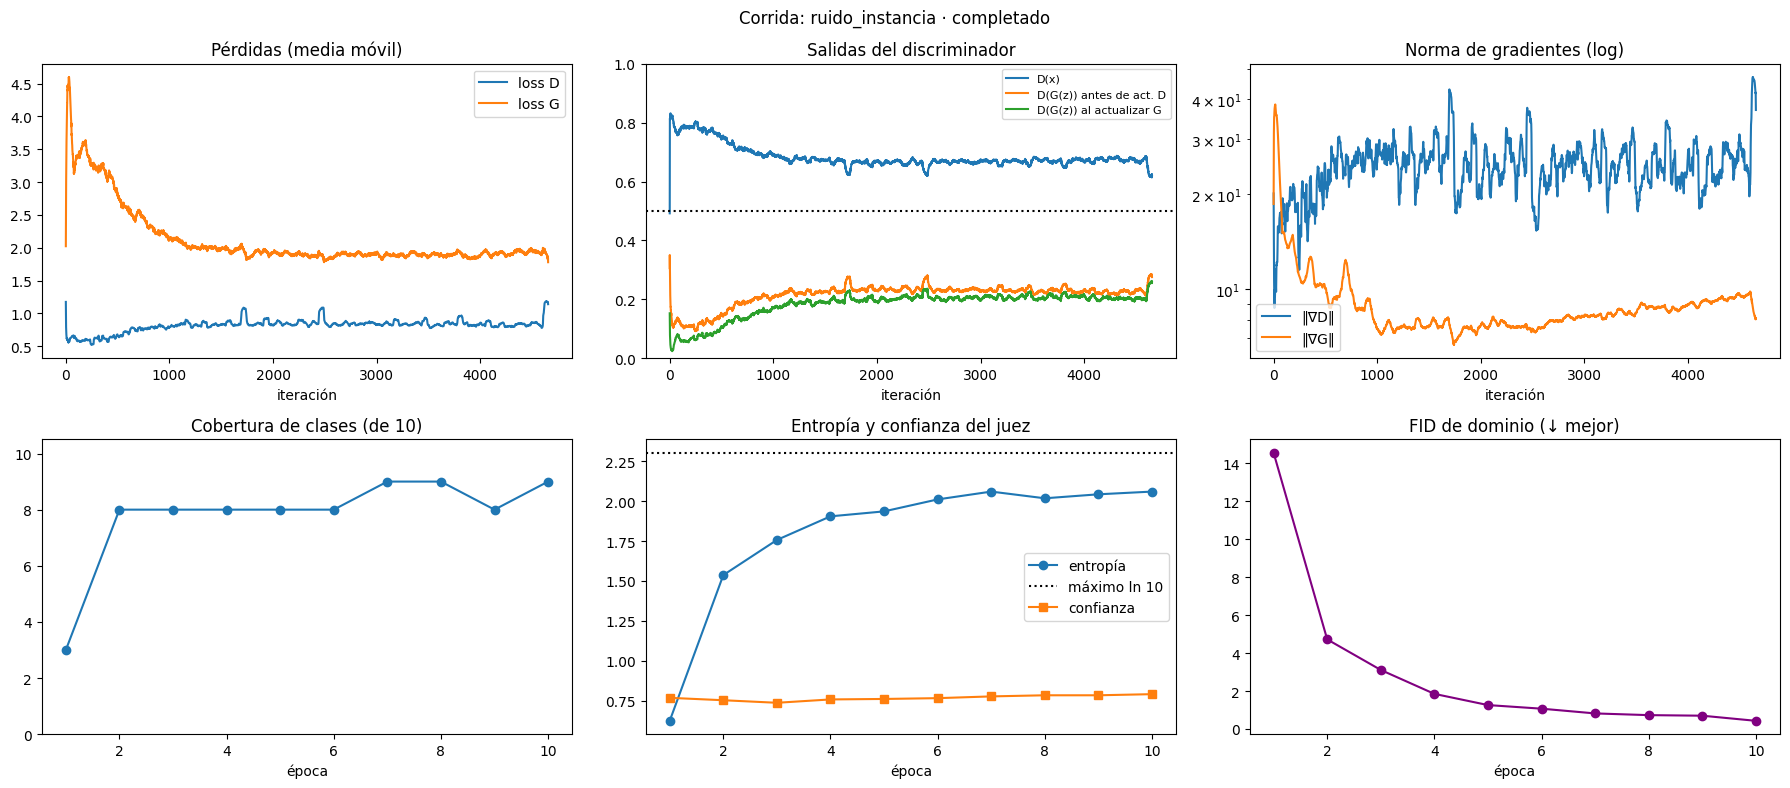

Sin alertas


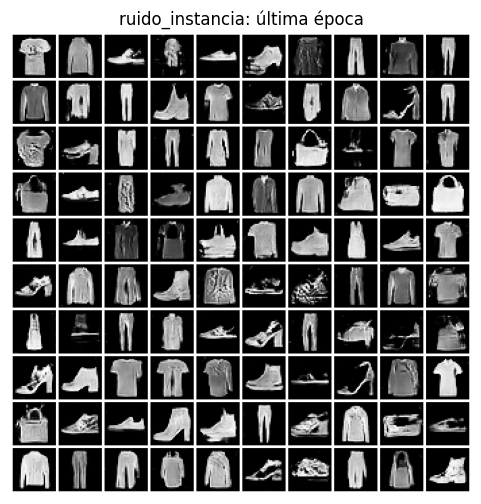

In [14]:
#Ejecutar variantes y comparar
EQUIPO = 7          #
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,225.0,9,2.03,0.787,0.70,0.70,0.671,0.228,Sin alertas
1,ruido_instancia,completado,228.6,9,2.06,0.791,0.43,0.43,0.669,0.230,Sin alertas


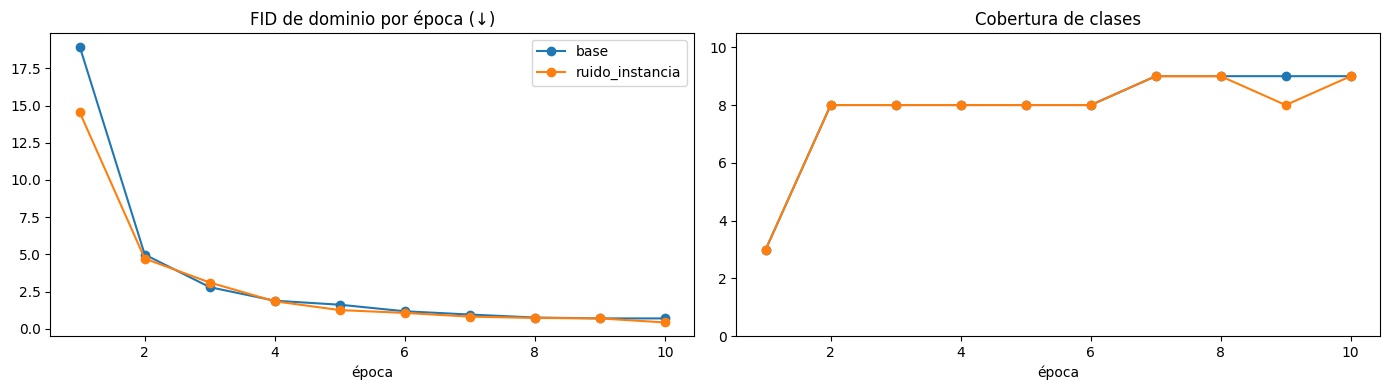

In [15]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

Como impacto la ablacion?

**Impacto con el ruido de instancia  mejoró el FID de dominio final bajándolo de 0.70 (base) a 0.43 (variante), manteniendo una excelente cobertura de 9/10 clases y sin generar alertas.**

¿Qué estrategias de estabilización fueron **imprescindibles** y cuáles **marginales** en este problema?

- **Imprescindibles:**
  - **BatchNorm (bn=False): Sin él, el FID de dominio empeoró de 0.70 a 3.5 y la cobertura cayó a 7/10 (alerta de colapso de modo).**
  - **Inicialización correcta: Clave para evitar divergencias o desequilibrios desde las primeras iteraciones.**
- **Marginales:
Ruido de instancia / Suavizado No evita que el modelo aprenda, pero actúan como regularizadores que pulen la calidad de las imágenes y mejoran el FID final**

## Parte G Explorar el espacio latente

Si G aprendió una representación útil, moverse **suavemente** en $z$ debe producir cambios **suaves** en la imagen. Interpolamos con *slerp* (interpolación esférica), recomendada para ruido gaussiano en alta dimensión.

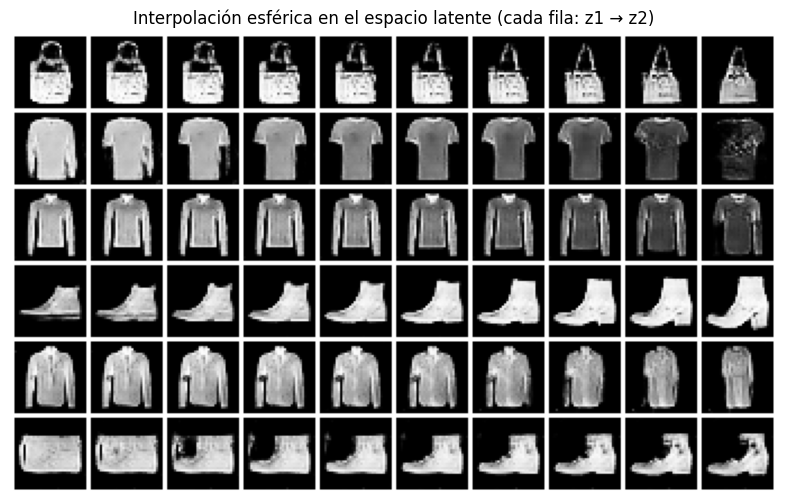

Generador(
  (red): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Tanh()
  )
)

In [16]:
def slerp(z1, z2, t):
    omega = torch.acos(((z1 / z1.norm()) * (z2 / z2.norm())).sum().clamp(-1, 1))
    return (torch.sin((1 - t) * omega) * z1 + torch.sin(t * omega) * z2) / torch.sin(omega)

G = base["G"].eval(); fijar_semilla(7)
filas = []
for _ in range(6):
    z1, z2 = torch.randn(CFG_BASE["nz"], device=DEVICE), torch.randn(CFG_BASE["nz"], device=DEVICE)
    filas.append(torch.stack([slerp(z1, z2, t) for t in torch.linspace(0, 1, 10)]))
with torch.no_grad():
    imgs = G(torch.cat(filas))
mostrar_grid(imgs, "Interpolación esférica en el espacio latente (cada fila: z1 → z2)", nrow=10, tam=(10, 6))
G.train()

¿Las transiciones son suaves o hay "saltos" de clase?

- **En las filas 1–3 (transiciones dentro de una "familia"): son típicamente suaves, el zapato que gira, una sudadera que cambia de tono, un bolso que cambia de forma, indica que G aprendió direcciones semánticas continuas.**

- **En las filas 4–6 (transiciones entre clases): aparecen saltos o "promedios raros" en la mitad, eje. un zapato que en t=0.5 se ve como una "mancha" y en t=1 es una camiseta, es normal el espacio latente no está perfectamente organizado por clase (a diferencia de una cGAN) que está organizado por factores de variación compartidos (forma, textura, brillo).**


¿Qué te dice eso sobre el espacio latente que aprendió G?

**Las transiciones suaves indican que G no memorizó las muestras y que interpoló de forma coherente y con los pocos 'saltos' son esperables porque el espacio latente no está condicionado por clase y al cruzar la frontera entre dos modos.**

In [17]:
from PIL import Image as PILImage
def guardar_gif(res, ruta):
    cuadros = []
    for g in res["rejillas"]:
        r = make_grid(g, nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
        cuadros.append(PILImage.fromarray((r.permute(1, 2, 0).numpy() * 255).astype("uint8")))
    if cuadros: cuadros[0].save(ruta, save_all=True, append_images=cuadros[1:], duration=600, loop=0)

for res in [base, variante]:
    n = res["cfg"]["nombre"]
    torch.save({"G": res["G"].state_dict(), "cfg": res["cfg"]}, f"G_dcgan_{n}.pt")
    res["registro"].to_csv(f"registro_{n}.csv", index=False)
    res["por_epoca"].drop(columns="frecuencias").to_csv(f"metricas_{n}.csv", index=False)
    guardar_gif(res, f"progreso_{n}.gif")
print(sorted(f for f in os.listdir(".") if f.endswith((".pt", ".csv", ".gif", ".png"))))
# from google.colab import files; files.download("G_dcgan_base.pt"); files.download(JUEZ_RUTA)

['G_dcgan_base.pt', 'G_dcgan_ruido_instancia.pt', 'ablacion_equipo7.csv', 'ablacion_equipo7.png', 'curvas_base.png', 'curvas_ruido_instancia.png', 'juez_FashionMNIST.pt', 'metricas_base.csv', 'metricas_ruido_instancia.csv', 'progreso_base.gif', 'progreso_ruido_instancia.gif', 'registro_base.csv', 'registro_ruido_instancia.csv']
